In [1]:
import pandas as pd

In [2]:
pd.read_csv("/content/users (1).csv")

,user_id,name,age,location,profession,experience_years,professional_summary,about_me,mbti,interests
0,U001,Pooja Kulkarni,29,Bangalore,Operations Manager,6,6 years of hands-on experience as an Operation...,I am energised by talking to people and bounci...,ESTJ,"Cricket, Gardening, Hiking, Fitness"
1,U002,Sneha Banerjee,26,Bangalore,Senior Financial Analyst,5,Working as a Senior Financial Analyst in finte...,I am energised by talking to people and bounci...,ESTJ,"Investing, Cricket, Painting, Photography"
2,U003,Deepak Menon,32,Mumbai,Lead DevOps Engineer,9,Working as a Lead DevOps Engineer in banking t...,I prefer deep one-on-one conversations over la...,ISTP,"Home Lab, Cycling, Cooking"
3,U004,Divya Singh,33,Bangalore,Startup Founder,9,Startup Founder with 9 years of experience in ...,I enjoy being in the middle of group discussio...,ENFJ,"Public Speaking, Running, Writing, Cricket"
4,U005,Meera Bhat,29,Chennai,Senior Software Engineer,8,8 years of hands-on experience as a Senior Sof...,I recharge by spending quiet time alone before...,ISFP,"Gaming, Gadgets, Music"
...,...,...,...,...,...,...,...,...,...,...
85,U086,Gaurav Banerjee,25,Hyderabad,Startup Founder,4,Startup Founder in the health and wellness spa...,I think best out loud and love brainstorming w...,ENTJ,"Podcasts, Startups, Running"
86,U087,Pallavi Banerjee,31,Kolkata,Senior Financial Analyst,9,Senior Financial Analyst with 9 years of exper...,I think best out loud and love brainstorming w...,ESTJ,"Chess, Cricket, Painting, Podcasts"
87,U088,Swati Kulkarni,28,Pune,Data Analyst,4,4 years of hands-on experience as a Data Analy...,I enjoy being in the middle of group discussio...,ESTJ,"Teaching, Data Visualization, Cricket, Travel"
88,U089,Priya Reddy,35,Pune,Senior Product Manager,10,10 years of hands-on experience as a Senior Pr...,I enjoy being in the middle of group discussio...,ENTJ,"Travel, Public Speaking, Yoga"


In [3]:

users = pd.read_csv("/content/users (1).csv")
feedback = pd.read_csv("/content/feedback.csv")

In [4]:
print(users.head())


  user_id            name  age   location                profession  \
0    U001  Pooja Kulkarni   29  Bangalore        Operations Manager   
1    U002  Sneha Banerjee   26  Bangalore  Senior Financial Analyst   
2    U003    Deepak Menon   32     Mumbai      Lead DevOps Engineer   
3    U004     Divya Singh   33  Bangalore           Startup Founder   
4    U005      Meera Bhat   29    Chennai  Senior Software Engineer   

   experience_years                               professional_summary  \
0                 6  6 years of hands-on experience as an Operation...   
1                 5  Working as a Senior Financial Analyst in finte...   
2                 9  Working as a Lead DevOps Engineer in banking t...   
3                 9  Startup Founder with 9 years of experience in ...   
4                 8  8 years of hands-on experience as a Senior Sof...   

                                            about_me  mbti  \
0  I am energised by talking to people and bounci...  ESTJ   
1  I

In [5]:
print(feedback.head())

  user_id matched_user_id  action   timestamp
0    U001            U087       0  2025-03-30
1    U001            U063       0  2025-01-05
2    U001            U039       0  2025-03-10
3    U001            U052       0  2025-01-11
4    U001            U033       0  2025-01-22


In [6]:
print(users.shape)
print(feedback.shape)

(90, 10)
(673, 4)


In [7]:
print(users["user_id"].is_unique)

True


In [8]:
print("Empty cells in users:")
print(users.isna().sum())

print()

print("Empty cells in feedback:")
print(feedback.isna().sum())

Empty cells in users:
user_id                 0
name                    0
age                     0
location                0
profession              0
experience_years        0
professional_summary    0
about_me                0
mbti                    0
interests               0
dtype: int64

Empty cells in feedback:
user_id            0
matched_user_id    0
action             0
timestamp          0
dtype: int64


In [9]:
print("Duplicate rows in users:", users.duplicated().sum())
print("Duplicate rows in feedback:", feedback.duplicated().sum())

Duplicate rows in users: 0
Duplicate rows in feedback: 0


In [10]:
allowed_mbti = [
    "INTJ", "INTP", "ENTJ", "ENTP",
    "INFJ", "INFP", "ENFJ", "ENFP",
    "ISTJ", "ISFJ", "ESTJ", "ESFJ",
    "ISTP", "ISFP", "ESTP", "ESFP"
]

print(users["mbti"].isin(allowed_mbti).all())

True


In [11]:
print(feedback["action"].unique())

[0 1]


In [12]:
accept_rate = feedback["action"].mean()

print("Accept rate:", accept_rate)
print("Accept rate (%):", accept_rate * 100)

Accept rate: 0.40564635958395245
Accept rate (%): 40.56463595839524


In [13]:
users["mbti"].value_counts()

,count
mbti,
ESTJ,11
ISTP,9
ENTJ,8
ISTJ,8
ENFP,8
ENTP,8
INTJ,8
INTP,7
ENFJ,5


In [14]:
import matplotlib.pyplot as plt

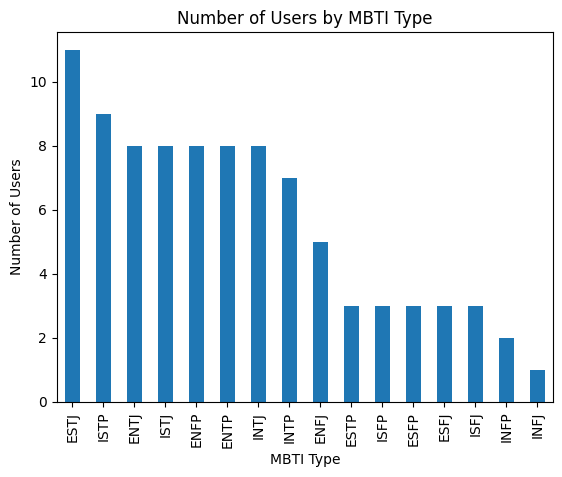

In [15]:
users["mbti"].value_counts().plot(kind="bar")

plt.title("Number of Users by MBTI Type")
plt.xlabel("MBTI Type")
plt.ylabel("Number of Users")

plt.show()

In [16]:
import nltk
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [17]:
from nltk.corpus import stopwords
len(stopwords.words("english"))

198

In [18]:
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    words = text.split()
    words = [word for word in words if word not in stop_words]
    words = [lemmatizer.lemmatize(word) for word in words]
    return " ".join(words)

In [19]:
original = users["about_me"].iloc[0]
cleaned = clean_text(original)
print("BEFORE:")
print(original)
print("\nAFTER:")
print(cleaned)

BEFORE:
I am energised by talking to people and bouncing ideas around the team. I keep my work organised with clear priorities and timelines. I enjoy mentoring juniors and sharing what I have learned along the way. I value integrity and honesty, and outside work I enjoy cricket, gardening, and hiking.

AFTER:
energised talking people bouncing idea around team keep work organised clear priority timeline enjoy mentoring junior sharing learned along way value integrity honesty outside work enjoy cricket gardening hiking


In [20]:
users["about_clean"] = users["about_me"].apply(clean_text)
users["summary_clean"] = users["professional_summary"].apply(clean_text)

In [21]:
print("Empty about_clean:",(users["about_clean"] == "").sum())
print("Empty summary_clean:",(users["summary_clean"] == "").sum())

Empty about_clean: 0
Empty summary_clean: 0


In [22]:
print("Python occurrences:", users["summary_clean"].str.contains("python", case=False).sum())
print("SQL occurrences:", users["summary_clean"].str.contains("sql", case=False).sum())

Python occurrences: 8
SQL occurrences: 8


In [23]:
users[[
    "user_id",
    "professional_summary",
    "summary_clean",
    "about_me",
    "about_clean"
]].head()

,user_id,professional_summary,summary_clean,about_me,about_clean
0,U001,6 years of hands-on experience as an Operation...,year hand experience operation manager logisti...,I am energised by talking to people and bounci...,energised talking people bouncing idea around ...
1,U002,Working as a Senior Financial Analyst in finte...,working senior financial analyst fintech using...,I am energised by talking to people and bounci...,energised talking people bouncing idea around ...
2,U003,Working as a Lead DevOps Engineer in banking t...,working lead devops engineer banking technolog...,I prefer deep one-on-one conversations over la...,prefer deep one one conversation large crowd m...
3,U004,Startup Founder with 9 years of experience in ...,startup founder year experience ed tech skille...,I enjoy being in the middle of group discussio...,enjoy middle group discussion meeting new peop...
4,U005,8 years of hands-on experience as a Senior Sof...,year hand experience senior software engineer ...,I recharge by spending quiet time alone before...,recharge spending quiet time alone taking next...


In [24]:
users.to_csv("users_clean.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [25]:
clean_users = pd.read_csv("users_clean.csv")

print("Rows:", clean_users.shape[0])
print("Columns:", clean_users.shape[1])
print(clean_users[["user_id", "about_clean", "summary_clean"]].head())

Rows: 90
Columns: 12
  user_id                                        about_clean  \
0    U001  energised talking people bouncing idea around ...   
1    U002  energised talking people bouncing idea around ...   
2    U003  prefer deep one one conversation large crowd m...   
3    U004  enjoy middle group discussion meeting new peop...   
4    U005  recharge spending quiet time alone taking next...   

                                       summary_clean  
0  year hand experience operation manager logisti...  
1  working senior financial analyst fintech using...  
2  working lead devops engineer banking technolog...  
3  startup founder year experience ed tech skille...  
4  year hand experience senior software engineer ...  


In [26]:
%%writefile data_pipeline.py

import pandas as pd
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


def load_data():
    users = pd.read_csv("users.csv")
    feedback = pd.read_csv("feedback.csv")

    return users, feedback

Writing data_pipeline.py


In [27]:
import importlib
import data_pipeline

importlib.reload(data_pipeline)

print("data_pipeline reloaded successfully!")

data_pipeline reloaded successfully!


In [28]:
print(open("data_pipeline.py").read())


import pandas as pd
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


def load_data():
    users = pd.read_csv("users.csv")
    feedback = pd.read_csv("feedback.csv")

    return users, feedback



In [29]:
from data_pipeline import load_data

print("load_data imported successfully!")

load_data imported successfully!


In [30]:
import os

print(os.listdir())

['.config', 'users (1).csv', 'feedback.csv', 'users_clean.csv', '__pycache__', 'data_pipeline.py', 'sample_data']


In [31]:
import os

os.rename("users (1).csv", "users.csv")

print("users.csv created successfully!")

users.csv created successfully!


In [32]:
from data_pipeline import load_data

users, feedback = load_data()

print("Users shape:", users.shape)
print("Feedback shape:", feedback.shape)

Users shape: (90, 10)
Feedback shape: (673, 4)


In [33]:
print("Users columns:")
print(users.columns.tolist())

print("\nFeedback columns:")
print(feedback.columns.tolist())

Users columns:
['user_id', 'name', 'age', 'location', 'profession', 'experience_years', 'professional_summary', 'about_me', 'mbti', 'interests']

Feedback columns:
['user_id', 'matched_user_id', 'action', 'timestamp']


In [34]:
%%writefile data_pipeline.py

import pandas as pd
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


def load_data():
    users = pd.read_csv("users.csv")
    feedback = pd.read_csv("feedback.csv")

    return users, feedback


def validate_users(users):

    # 1. Check that every user_id is unique
    if not users["user_id"].is_unique:
        raise ValueError("Duplicate user_id found.")

    # 2. Check that all MBTI types are valid
    valid_mbti = [
        "INTJ", "INTP", "ENTJ", "ENTP",
        "INFJ", "INFP", "ENFJ", "ENFP",
        "ISTJ", "ISFJ", "ESTJ", "ESFJ",
        "ISTP", "ISFP", "ESTP", "ESFP"
    ]

    if not users["mbti"].isin(valid_mbti).all():
        raise ValueError("Invalid MBTI type found.")

    # 3. Check that required text fields are not empty
    for column in ["professional_summary", "about_me"]:
        if users[column].isna().any():
            raise ValueError(f"Missing value found in {column}.")

        if (users[column].astype(str).str.strip() == "").any():
            raise ValueError(f"Empty text found in {column}.")

    # 4. Check for duplicate rows
    if users.duplicated().any():
        raise ValueError("Duplicate rows found in users dataset.")

    # 5. Check age range
    if not users["age"].between(20, 45).all():
        raise ValueError("Age must be between 20 and 45.")

    print("Users validation passed!")

Overwriting data_pipeline.py


In [35]:
import importlib
import data_pipeline

importlib.reload(data_pipeline)

print("data_pipeline reloaded successfully!")

data_pipeline reloaded successfully!


In [36]:
from data_pipeline import validate_users

validate_users(users)

Users validation passed!


In [37]:
%%writefile data_pipeline.py

import pandas as pd
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


def load_data():
    users = pd.read_csv("users.csv")
    feedback = pd.read_csv("feedback.csv")

    return users, feedback


def validate_users(users):

    # 1. Check that every user_id is unique
    if not users["user_id"].is_unique:
        raise ValueError("Duplicate user_id found.")

    # 2. Check that all MBTI types are valid
    valid_mbti = [
        "INTJ", "INTP", "ENTJ", "ENTP",
        "INFJ", "INFP", "ENFJ", "ENFP",
        "ISTJ", "ISFJ", "ESTJ", "ESFJ",
        "ISTP", "ISFP", "ESTP", "ESFP"
    ]

    if not users["mbti"].isin(valid_mbti).all():
        raise ValueError("Invalid MBTI type found.")

    # 3. Check that required text fields are not empty
    for column in ["professional_summary", "about_me"]:
        if users[column].isna().any():
            raise ValueError(f"Missing value found in {column}.")

        if (users[column].astype(str).str.strip() == "").any():
            raise ValueError(f"Empty text found in {column}.")

    # 4. Check for duplicate rows
    if users.duplicated().any():
        raise ValueError("Duplicate rows found in users dataset.")

    # 5. Check age range
    if not users["age"].between(20, 45).all():
        raise ValueError("Age must be between 20 and 45.")

    print("Users validation passed!")


def validate_feedback(feedback, users):

    # 1. Check that action contains only 0 or 1
    if not feedback["action"].isin([0, 1]).all():
        raise ValueError("Action must contain only 0 or 1.")

    # 2. Check that every user_id exists in users
    if not feedback["user_id"].isin(users["user_id"]).all():
        raise ValueError("Feedback contains an unknown user_id.")

    # 3. Check that every matched_user_id exists in users
    if not feedback["matched_user_id"].isin(users["user_id"]).all():
        raise ValueError("Feedback contains an unknown matched_user_id.")

    # 4. Check that users are not matched with themselves
    if (feedback["user_id"] == feedback["matched_user_id"]).any():
        raise ValueError("Self-match found in feedback.")

    print("Feedback validation passed!")

Overwriting data_pipeline.py


In [38]:
import importlib
import data_pipeline

importlib.reload(data_pipeline)

print("data_pipeline reloaded successfully!")

data_pipeline reloaded successfully!


In [39]:
from data_pipeline import validate_feedback

validate_feedback(feedback, users)

Feedback validation passed!


In [40]:
%%writefile data_pipeline.py

import pandas as pd
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


def load_data():
    users = pd.read_csv("users.csv")
    feedback = pd.read_csv("feedback.csv")

    return users, feedback


def validate_users(users):

    # 1. Check that every user_id is unique
    if not users["user_id"].is_unique:
        raise ValueError("Duplicate user_id found.")

    # 2. Check that all MBTI types are valid
    valid_mbti = [
        "INTJ", "INTP", "ENTJ", "ENTP",
        "INFJ", "INFP", "ENFJ", "ENFP",
        "ISTJ", "ISFJ", "ESTJ", "ESFJ",
        "ISTP", "ISFP", "ESTP", "ESFP"
    ]

    if not users["mbti"].isin(valid_mbti).all():
        raise ValueError("Invalid MBTI type found.")

    # 3. Check that required text fields are not empty
    for column in ["professional_summary", "about_me"]:
        if users[column].isna().any():
            raise ValueError(f"Missing value found in {column}.")

        if (users[column].astype(str).str.strip() == "").any():
            raise ValueError(f"Empty text found in {column}.")

    # 4. Check for duplicate rows
    if users.duplicated().any():
        raise ValueError("Duplicate rows found in users dataset.")

    # 5. Check age range
    if not users["age"].between(20, 45).all():
        raise ValueError("Age must be between 20 and 45.")

    print("Users validation passed!")


def validate_feedback(feedback, users):

    # 1. Check that action contains only 0 or 1
    if not feedback["action"].isin([0, 1]).all():
        raise ValueError("Action must contain only 0 or 1.")

    # 2. Check that every user_id exists in users
    if not feedback["user_id"].isin(users["user_id"]).all():
        raise ValueError("Feedback contains an unknown user_id.")

    # 3. Check that every matched_user_id exists in users
    if not feedback["matched_user_id"].isin(users["user_id"]).all():
        raise ValueError("Feedback contains an unknown matched_user_id.")

    # 4. Check that users are not matched with themselves
    if (feedback["user_id"] == feedback["matched_user_id"]).any():
        raise ValueError("Self-match found in feedback.")

    print("Feedback validation passed!")


def clean_text(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove numbers and special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # Split text into individual words
    words = text.split()

    # Remove stopwords
    words = [word for word in words if word not in stop_words]

    # Lemmatize words
    words = [lemmatizer.lemmatize(word) for word in words]

    return " ".join(words)

Overwriting data_pipeline.py


In [41]:
import importlib
import data_pipeline

importlib.reload(data_pipeline)

print("data_pipeline reloaded successfully!")

data_pipeline reloaded successfully!


In [42]:
import data_pipeline

print("stop_words exists:", hasattr(data_pipeline, "stop_words"))
print("lemmatizer exists:", hasattr(data_pipeline, "lemmatizer"))

stop_words exists: False
lemmatizer exists: False


In [43]:
print(open("data_pipeline.py").read())


import pandas as pd
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


def load_data():
    users = pd.read_csv("users.csv")
    feedback = pd.read_csv("feedback.csv")

    return users, feedback


def validate_users(users):

    # 1. Check that every user_id is unique
    if not users["user_id"].is_unique:
        raise ValueError("Duplicate user_id found.")

    # 2. Check that all MBTI types are valid
    valid_mbti = [
        "INTJ", "INTP", "ENTJ", "ENTP",
        "INFJ", "INFP", "ENFJ", "ENFP",
        "ISTJ", "ISFJ", "ESTJ", "ESFJ",
        "ISTP", "ISFP", "ESTP", "ESFP"
    ]

    if not users["mbti"].isin(valid_mbti).all():
        raise ValueError("Invalid MBTI type found.")

    # 3. Check that required text fields are not empty
    for column in ["professional_summary", "about_me"]:
        if users[column].isna().any():
            raise ValueError(f"Missing value found in {column}.")

        if (users[column].astype(str).str.strip() =

In [44]:
%%writefile data_pipeline.py

import pandas as pd
import re
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


# NLP setup
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()


def load_data():
    users = pd.read_csv("users.csv")
    feedback = pd.read_csv("feedback.csv")

    return users, feedback


def validate_users(users):

    if not users["user_id"].is_unique:
        raise ValueError("Duplicate user_id found.")

    valid_mbti = [
        "INTJ", "INTP", "ENTJ", "ENTP",
        "INFJ", "INFP", "ENFJ", "ENFP",
        "ISTJ", "ISFJ", "ESTJ", "ESFJ",
        "ISTP", "ISFP", "ESTP", "ESFP"
    ]

    if not users["mbti"].isin(valid_mbti).all():
        raise ValueError("Invalid MBTI type found.")

    for column in ["professional_summary", "about_me"]:
        if users[column].isna().any():
            raise ValueError(f"Missing value found in {column}.")

        if (users[column].astype(str).str.strip() == "").any():
            raise ValueError(f"Empty text found in {column}.")

    if users.duplicated().any():
        raise ValueError("Duplicate rows found in users dataset.")

    if not users["age"].between(20, 45).all():
        raise ValueError("Age must be between 20 and 45.")

    print("Users validation passed!")


def validate_feedback(feedback, users):

    if not feedback["action"].isin([0, 1]).all():
        raise ValueError("Action must contain only 0 or 1.")

    if not feedback["user_id"].isin(users["user_id"]).all():
        raise ValueError("Feedback contains an unknown user_id.")

    if not feedback["matched_user_id"].isin(users["user_id"]).all():
        raise ValueError("Feedback contains an unknown matched_user_id.")

    if (feedback["user_id"] == feedback["matched_user_id"]).any():
        raise ValueError("Self-match found in feedback.")

    print("Feedback validation passed!")


def clean_text(text):

    text = text.lower()

    text = re.sub(r"[^a-z\s]", " ", text)

    words = text.split()

    words = [word for word in words if word not in stop_words]

    words = [lemmatizer.lemmatize(word) for word in words]

    return " ".join(words)

Overwriting data_pipeline.py


In [45]:
import importlib
import data_pipeline

importlib.reload(data_pipeline)

print("data_pipeline reloaded successfully!")

data_pipeline reloaded successfully!


In [46]:
from data_pipeline import clean_text

text = users["about_me"].iloc[0]

print("BEFORE:")
print(text)

print("\nAFTER:")
print(clean_text(text))

BEFORE:
I am energised by talking to people and bouncing ideas around the team. I keep my work organised with clear priorities and timelines. I enjoy mentoring juniors and sharing what I have learned along the way. I value integrity and honesty, and outside work I enjoy cricket, gardening, and hiking.

AFTER:
energised talking people bouncing idea around team keep work organised clear priority timeline enjoy mentoring junior sharing learned along way value integrity honesty outside work enjoy cricket gardening hiking


In [47]:
%%writefile data_pipeline.py

import pandas as pd
import re
import os
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


# NLP setup
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()


def load_data():
    users = pd.read_csv("users.csv")
    feedback = pd.read_csv("feedback.csv")

    return users, feedback


def validate_users(users):

    if not users["user_id"].is_unique:
        raise ValueError("Duplicate user_id found.")

    valid_mbti = [
        "INTJ", "INTP", "ENTJ", "ENTP",
        "INFJ", "INFP", "ENFJ", "ENFP",
        "ISTJ", "ISFJ", "ESTJ", "ESFJ",
        "ISTP", "ISFP", "ESTP", "ESFP"
    ]

    if not users["mbti"].isin(valid_mbti).all():
        raise ValueError("Invalid MBTI type found.")

    for column in ["professional_summary", "about_me"]:
        if users[column].isna().any():
            raise ValueError(f"Missing value found in {column}.")

        if (users[column].astype(str).str.strip() == "").any():
            raise ValueError(f"Empty text found in {column}.")

    if users.duplicated().any():
        raise ValueError("Duplicate rows found in users dataset.")

    if not users["age"].between(20, 45).all():
        raise ValueError("Age must be between 20 and 45.")

    print("Users validation passed!")


def validate_feedback(feedback, users):

    if not feedback["action"].isin([0, 1]).all():
        raise ValueError("Action must contain only 0 or 1.")

    if not feedback["user_id"].isin(users["user_id"]).all():
        raise ValueError("Feedback contains an unknown user_id.")

    if not feedback["matched_user_id"].isin(users["user_id"]).all():
        raise ValueError("Feedback contains an unknown matched_user_id.")

    if (feedback["user_id"] == feedback["matched_user_id"]).any():
        raise ValueError("Self-match found in feedback.")

    print("Feedback validation passed!")


def clean_text(text):

    text = text.lower()

    text = re.sub(r"[^a-z\s]", " ", text)

    words = text.split()

    words = [word for word in words if word not in stop_words]

    words = [lemmatizer.lemmatize(word) for word in words]

    return " ".join(words)


def build_clean_users(users):

    users["summary_clean"] = users["professional_summary"].apply(clean_text)
    users["about_clean"] = users["about_me"].apply(clean_text)

    os.makedirs("data", exist_ok=True)

    users.to_csv("data/users_clean.csv", index=False)

    print("Cleaned users dataset saved successfully!")

    return users

Overwriting data_pipeline.py


In [48]:
import importlib
import data_pipeline

importlib.reload(data_pipeline)

print("data_pipeline reloaded successfully!")

data_pipeline reloaded successfully!


In [49]:
from data_pipeline import build_clean_users

clean_users = build_clean_users(users)

Cleaned users dataset saved successfully!


In [50]:
import os

print("File exists:", os.path.exists("data/users_clean.csv"))

File exists: True


In [51]:
clean_users = pd.read_csv("data/users_clean.csv")

print(clean_users[[
    "user_id",
    "summary_clean",
    "about_clean"
]].head())

  user_id                                      summary_clean  \
0    U001  year hand experience operation manager logisti...   
1    U002  working senior financial analyst fintech using...   
2    U003  working lead devops engineer banking technolog...   
3    U004  startup founder year experience ed tech skille...   
4    U005  year hand experience senior software engineer ...   

                                         about_clean  
0  energised talking people bouncing idea around ...  
1  energised talking people bouncing idea around ...  
2  prefer deep one one conversation large crowd m...  
3  enjoy middle group discussion meeting new peop...  
4  recharge spending quiet time alone taking next...  


In [52]:
#2 columns added due to cleaned ones
print("Rows:", clean_users.shape[0])
print("Columns:", clean_users.shape[1])

Rows: 90
Columns: 12


In [53]:
#did to verify,ensure that the dataset follows the required rules before we use it for NLP, matching, or machine learning. This prevents incorrect data from entering later stages of the project
from data_pipeline import load_data, validate_users, validate_feedback

users, feedback = load_data()

validate_users(users)
validate_feedback(feedback, users)

Users validation passed!
Feedback validation passed!


In [54]:
from sklearn.feature_extraction.text import TfidfVectorizer

summary_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    ngram_range=(1, 2)
)

summary_matrix = summary_vectorizer.fit_transform(
    clean_users["summary_clean"]
)

print("Summary matrix shape:", summary_matrix.shape)

Summary matrix shape: (90, 1387)


In [55]:
from sklearn.metrics.pairwise import cosine_similarity

summary_similarity = cosine_similarity(summary_matrix)

print("Summary similarity shape:", summary_similarity.shape)

Summary similarity shape: (90, 90)


In [56]:
about_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    ngram_range=(1, 2)
)

about_matrix = about_vectorizer.fit_transform(
    clean_users["about_clean"]
)

print("About Me matrix shape:", about_matrix.shape)

About Me matrix shape: (90, 891)


In [57]:
about_similarity = cosine_similarity(about_matrix)

print("About Me similarity shape:", about_similarity.shape)

About Me similarity shape: (90, 90)


In [58]:
TextSim = (
    0.60 * summary_similarity
    + 0.40 * about_similarity
)

print("TextSim shape:", TextSim.shape)

TextSim shape: (90, 90)


In [59]:
print("User 1 self-similarity:", TextSim[0, 0])

User 1 self-similarity: 1.0000000000000004


In [60]:
user_index = 0

similar_scores = TextSim[user_index]

top_indices = similar_scores.argsort()[::-1][1:6]

print("User:", clean_users.iloc[user_index]["user_id"])
print("\nTop 5 most similar users:")

for i in top_indices:
    print(
        clean_users.iloc[i]["user_id"],
        "Similarity:",
        round(similar_scores[i], 3),
        "Profession:",
        clean_users.iloc[i]["profession"]
    )

User: U001

Top 5 most similar users:
U046 Similarity: 0.364 Profession: Operations Manager
U074 Similarity: 0.217 Profession: Senior Product Manager
U051 Similarity: 0.216 Profession: Operations Manager
U063 Similarity: 0.171 Profession: Senior Content Marketing Specialist
U088 Similarity: 0.168 Profession: Data Analyst


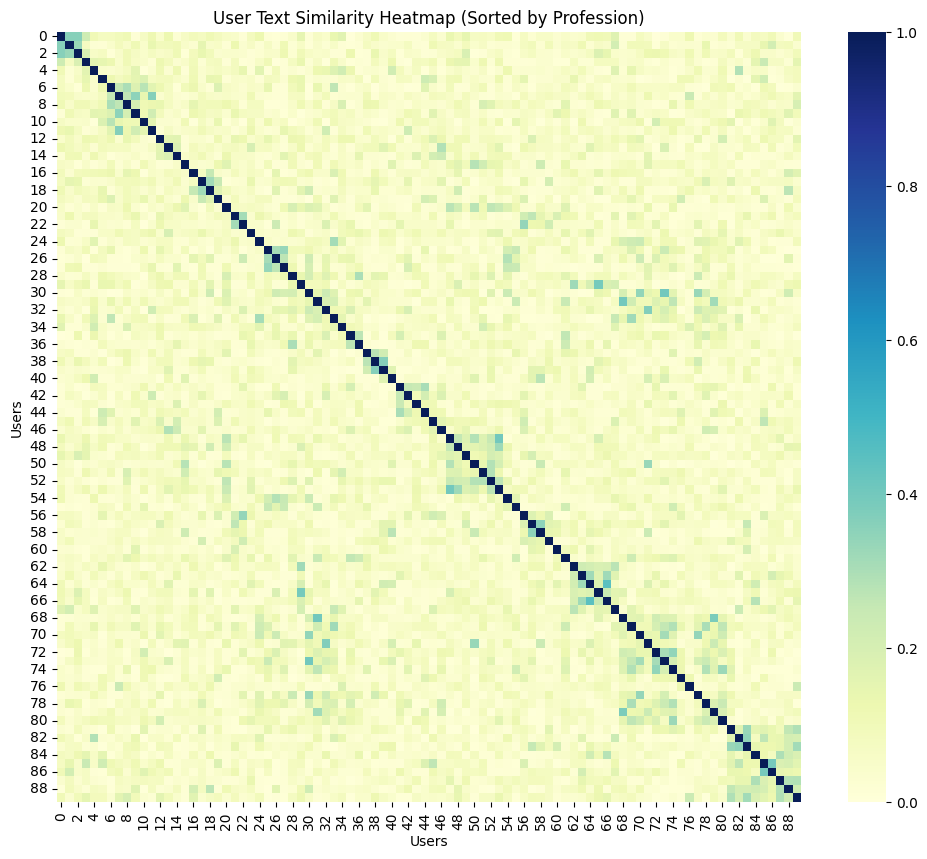

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sort users by profession
sorted_indices = clean_users.sort_values(
    "profession"
).index

# Rearrange the similarity matrix
sorted_similarity = TextSim[sorted_indices, :][:, sorted_indices]

# Draw heatmap
plt.figure(figsize=(12, 10))

sns.heatmap(
    sorted_similarity,
    cmap="YlGnBu"
)

plt.title("User Text Similarity Heatmap (Sorted by Profession)")
plt.xlabel("Users")
plt.ylabel("Users")
plt.show()

In [62]:
idx = {
    user_id: row
    for row, user_id in enumerate(clean_users["user_id"])
}

print("U001 index:", idx["U001"])
print("U046 index:", idx["U046"])

U001 index: 0
U046 index: 45


In [63]:
def text_sim(uid_a, uid_b):
    row_a = idx[uid_a]
    row_b = idx[uid_b]

    return TextSim[row_a, row_b]


print("U001 vs U046:", text_sim("U001", "U046"))

U001 vs U046: 0.3641106539932454


In [64]:
import joblib

joblib.dump(summary_vectorizer, "summary_vectorizer.pkl")
joblib.dump(about_vectorizer, "about_vectorizer.pkl")

print("Vectorizers saved successfully!")

Vectorizers saved successfully!


In [65]:
def mbti_score(mbti_a, mbti_b):

    score = 40

    # N/S: same gets points
    if mbti_a[1] == mbti_b[1]:
        score += 10

    # T/F: different gets points
    if mbti_a[2] != mbti_b[2]:
        score += 15

    # I/E: different gets points
    if mbti_a[0] != mbti_b[0]:
        score += 15

    # J/P: same gets points
    if mbti_a[3] == mbti_b[3]:
        score += 10

    return min(score, 100)


print("INTJ vs ENFP:", mbti_score("INTJ", "ENFP"))
print("INTJ vs INTJ:", mbti_score("INTJ", "INTJ"))

INTJ vs ENFP: 80
INTJ vs INTJ: 60


In [66]:
golden_pairs = {
    frozenset(["INTJ", "ENFP"]),
    frozenset(["INTP", "ENTJ"]),
    frozenset(["INFJ", "ENTP"]),
    frozenset(["INFP", "ENFJ"]),
    frozenset(["ISTJ", "ESFP"]),
    frozenset(["ISFJ", "ESTP"]),
    frozenset(["ISTP", "ESFJ"]),
    frozenset(["ISFP", "ESTJ"])
}

print("Number of golden pairs:", len(golden_pairs))

Number of golden pairs: 8


In [67]:
def mbti_score(mbti_a, mbti_b):

    # Golden pairs always get 100
    if frozenset([mbti_a, mbti_b]) in golden_pairs:
        return 100

    score = 40

    # N/S: same gets points
    if mbti_a[1] == mbti_b[1]:
        score += 10

    # T/F: different gets points
    if mbti_a[2] != mbti_b[2]:
        score += 15

    # I/E: different gets points
    if mbti_a[0] != mbti_b[0]:
        score += 15

    # J/P: same gets points
    if mbti_a[3] == mbti_b[3]:
        score += 10

    return min(score, 100)


print("INTJ + ENFP:", mbti_score("INTJ", "ENFP"))
print("ENFP + INTJ:", mbti_score("ENFP", "INTJ"))

INTJ + ENFP: 100
ENFP + INTJ: 100


In [68]:
import pandas as pd

mbti_types = [
    "INTJ", "INTP", "ENTJ", "ENTP",
    "INFJ", "INFP", "ENFJ", "ENFP",
    "ISTJ", "ISFJ", "ESTJ", "ESFJ",
    "ISTP", "ISFP", "ESTP", "ESFP"
]

mbti_table = pd.DataFrame(
    [
        [mbti_score(a, b) for b in mbti_types]
        for a in mbti_types
    ],
    index=mbti_types,
    columns=mbti_types
)

print("Table shape:", mbti_table.shape)
mbti_table

Table shape: (16, 16)


,INTJ,INTP,ENTJ,ENTP,INFJ,INFP,ENFJ,ENFP,ISTJ,ISFJ,ESTJ,ESFJ,ISTP,ISFP,ESTP,ESFP
INTJ,60,50,75,65,75,65,90,100,50,65,65,80,40,55,55,70
INTP,50,60,100,75,65,75,80,90,40,55,55,70,50,65,65,80
ENTJ,75,100,60,50,90,80,75,65,65,80,50,65,55,70,40,55
ENTP,65,75,50,60,100,90,65,75,55,70,40,55,65,80,50,65
INFJ,75,65,90,100,60,50,75,65,65,50,80,65,55,40,70,55
INFP,65,75,80,90,50,60,100,75,55,40,70,55,65,50,80,65
ENFJ,90,80,75,65,75,100,60,50,80,65,65,50,70,55,55,40
ENFP,100,90,65,75,65,75,50,60,70,55,55,40,80,65,65,50
ISTJ,50,40,65,55,65,55,80,70,60,75,75,90,50,65,65,100
ISFJ,65,55,80,70,50,40,65,55,75,60,90,75,65,50,100,65


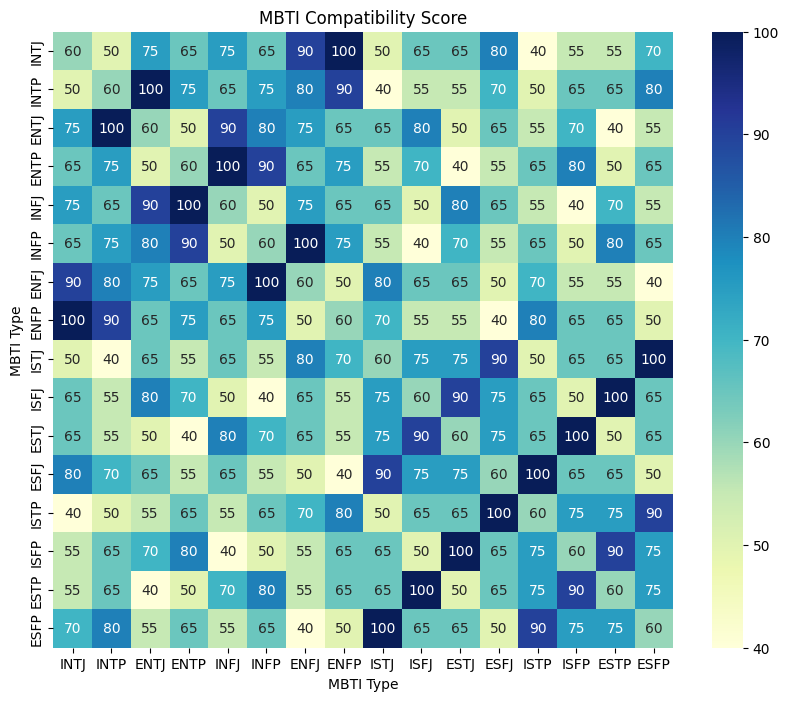

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    mbti_table,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("MBTI Compatibility Score")
plt.xlabel("MBTI Type")
plt.ylabel("MBTI Type")
plt.show()

In [70]:
assert mbti_score("INTJ", "ENFP") == 100

print("Check 1 passed!")

Check 1 passed!


In [71]:
for a in mbti_types:
    for b in mbti_types:
        assert mbti_score(a, b) == mbti_score(b, a)

print("Check 2 passed! MBTI scoring is symmetric.")

Check 2 passed! MBTI scoring is symmetric.


In [72]:
for a in mbti_types:
    for b in mbti_types:
        score = mbti_score(a, b)
        assert 0 <= score <= 100

print("Check 3 passed! All scores are between 0 and 100.")

Check 3 passed! All scores are between 0 and 100.


In [73]:
def location_score(uid_a, uid_b):
    city_a = clean_users.loc[idx[uid_a], "location"]
    city_b = clean_users.loc[idx[uid_b], "location"]

    if city_a == city_b:
        return 1.0
    else:
        return 0.0


print("U001 vs U046:", location_score("U001", "U046"))

U001 vs U046: 0.0


In [74]:
max_exp = clean_users["experience_years"].max()
min_exp = clean_users["experience_years"].min()

def experience_score(uid_a, uid_b):
    exp_a = clean_users.loc[idx[uid_a], "experience_years"]
    exp_b = clean_users.loc[idx[uid_b], "experience_years"]

    if max_exp == min_exp:
        return 1.0

    score = 1 - abs(exp_a - exp_b) / (max_exp - min_exp)

    return max(0, min(1, score))


print("U001 vs U046:", experience_score("U001", "U046"))

U001 vs U046: 0.4444444444444444


In [75]:
def interest_score(uid_a, uid_b):
    interests_a = set(
        str(clean_users.loc[idx[uid_a], "interests"]).lower().split(",")
    )

    interests_b = set(
        str(clean_users.loc[idx[uid_b], "interests"]).lower().split(",")
    )

    # Remove extra spaces
    interests_a = {interest.strip() for interest in interests_a}
    interests_b = {interest.strip() for interest in interests_b}

    shared_interests = interests_a.intersection(interests_b)

    score = len(shared_interests) / 2

    return min(score, 1.0)


print("U001 vs U046:", interest_score("U001", "U046"))

U001 vs U046: 1.0


In [76]:
import numpy as np

text_sim_95 = np.percentile(TextSim, 95)

print("95th percentile of TextSim:", text_sim_95)

95th percentile of TextSim: 0.21078585707667155


In [77]:
TextSim_scaled = np.clip(
    TextSim / text_sim_95,
    0,
    1
)

print("Scaled TextSim minimum:", TextSim_scaled.min())
print("Scaled TextSim maximum:", TextSim_scaled.max())

Scaled TextSim minimum: 0.0
Scaled TextSim maximum: 1.0


In [78]:
def mbti_scaled_score(uid_a, uid_b):
    mbti_a = clean_users.loc[idx[uid_a], "mbti"]
    mbti_b = clean_users.loc[idx[uid_b], "mbti"]

    return mbti_score(mbti_a, mbti_b) / 100


print("U001 vs U046:", mbti_scaled_score("U001", "U046"))

U001 vs U046: 0.5


In [79]:
def compatibility_score(uid_a, uid_b, weights):

    # Get row positions
    row_a = idx[uid_a]
    row_b = idx[uid_b]

    # Get individual feature scores
    text_score = TextSim_scaled[row_a, row_b]
    mbti_score_value = mbti_scaled_score(uid_a, uid_b)
    location_value = location_score(uid_a, uid_b)
    experience_value = experience_score(uid_a, uid_b)
    interest_value = interest_score(uid_a, uid_b)

    # Calculate weighted contributions
    text_contribution = weights["text"] * text_score
    mbti_contribution = weights["mbti"] * mbti_score_value
    location_contribution = weights["location"] * location_value
    experience_contribution = weights["experience"] * experience_value
    interest_contribution = weights["interests"] * interest_value

    # Final score
    total = (
        text_contribution
        + mbti_contribution
        + location_contribution
        + experience_contribution
        + interest_contribution
    )

    final_score = 100 * total

    return {
        "score": final_score,
        "text": text_contribution,
        "mbti": mbti_contribution,
        "location": location_contribution,
        "experience": experience_contribution,
        "interests": interest_contribution
    }


weights = {
    "text": 0.40,
    "mbti": 0.30,
    "location": 0.15,
    "experience": 0.15,
    "interests": 0.00
}

print(compatibility_score("U001", "U046", weights))

{'score': np.float64(61.66666666666667), 'text': np.float64(0.4), 'mbti': 0.15, 'location': 0.0, 'experience': np.float64(0.06666666666666667), 'interests': 0.0}


In [80]:
weight_sum = sum(weights.values())

print("Weight sum:", weight_sum)

assert weight_sum == 1.0

print("Weights check passed!")

Weight sum: 1.0
Weights check passed!


In [81]:
#check score range
result = compatibility_score("U001", "U046", weights)

score = result["score"]

print("Compatibility score:", score)

assert 0 <= score <= 100

print("Score range check passed!")

Compatibility score: 61.66666666666667
Score range check passed!


In [82]:
#check symmetry
score_ab = compatibility_score("U001", "U046", weights)["score"]
score_ba = compatibility_score("U046", "U001", weights)["score"]

print("U001 vs U046:", score_ab)
print("U046 vs U001:", score_ba)

assert np.isclose(score_ab, score_ba)

print("Symmetry check passed!")

U001 vs U046: 61.66666666666667
U046 vs U001: 61.66666666666667
Symmetry check passed!


In [83]:
def top_matches(uid, n=5):

    results = []

    for other_uid in clean_users["user_id"]:

        # Do not match the user with themselves
        if other_uid == uid:
            continue

        result = compatibility_score(uid, other_uid, weights)

        results.append({
            "user_id": other_uid,
            "score": result["score"]
        })

    results = pd.DataFrame(results)

    results = results.sort_values(
        "score",
        ascending=False
    )

    return results.head(n).reset_index(drop=True)


top5 = top_matches("U001", 5)

top5


,user_id,score
0,U002,77.331629
1,U037,76.106100
2,U023,72.239452
3,U031,70.662521
4,U074,69.500000


In [84]:
top5 = top_matches("U001", 5)

top5_details = top5.merge(
    clean_users[
        ["user_id", "name", "profession", "location", "mbti"]
    ],
    on="user_id"
)

top5_details

,user_id,score,name,profession,location,mbti
0,U002,77.331629,Sneha Banerjee,Senior Financial Analyst,Bangalore,ESTJ
1,U037,76.106100,Mohit Joshi,Senior Software Engineer,Bangalore,ISTJ
2,U023,72.239452,Pallavi Menon,Startup Founder,Bangalore,ISFJ
3,U031,70.662521,Arjun Pillai,Startup Founder,Bangalore,ENFJ
4,U074,69.500000,Rohan Chatterjee,Senior Product Manager,Hyderabad,ENFJ


In [85]:
#to check top matches r sorted
scores = top5["score"].values

assert all(scores[i] >= scores[i + 1] for i in range(len(scores) - 1))

print("Top matches sorting check passed!")
print("Scores:", list(scores))

Top matches sorting check passed!
Scores: [np.float64(77.33162899312556), np.float64(76.10609988358893), np.float64(72.2394524290363), np.float64(70.66252057432165), np.float64(69.5)]


In [86]:
training_data = []

for _, row in feedback.iterrows():

    uid_a = row["user_id"]
    uid_b = row["matched_user_id"]

    result = compatibility_score(uid_a, uid_b, weights)

    training_data.append({
        "text": TextSim_scaled[idx[uid_a], idx[uid_b]],
        "mbti": mbti_scaled_score(uid_a, uid_b),
        "location": location_score(uid_a, uid_b),
        "experience": experience_score(uid_a, uid_b),
        "interests": interest_score(uid_a, uid_b),
        "action": row["action"],
        "timestamp": row["timestamp"]
    })

training_df = pd.DataFrame(training_data)

print("Training table shape:", training_df.shape)
training_df.head()

Training table shape: (673, 7)


,text,mbti,location,experience,interests,action,timestamp
0,0.514177,0.60,0.0,0.833333,0.5,0,2025-03-30
1,0.809964,0.65,0.0,0.833333,0.0,0,2025-01-05
2,0.374947,0.55,0.0,0.722222,0.5,0,2025-03-10
3,0.124368,0.65,1.0,1.000000,0.0,0,2025-01-11
4,0.037963,0.65,0.0,0.666667,0.0,0,2025-01-22


In [87]:
training_data = []

for _, row in feedback.iterrows():

    uid_a = row["user_id"]
    uid_b = row["matched_user_id"]

    result = compatibility_score(uid_a, uid_b, weights)

    training_data.append({
        "text": TextSim_scaled[idx[uid_a], idx[uid_b]],
        "mbti": mbti_scaled_score(uid_a, uid_b),
        "location": location_score(uid_a, uid_b),
        "experience": experience_score(uid_a, uid_b),
        "interests": interest_score(uid_a, uid_b),
        "action": row["action"],
        "timestamp": row["timestamp"]
    })

training_df = pd.DataFrame(training_data)

print("Training table shape:", training_df.shape)
training_df.head()

Training table shape: (673, 7)


,text,mbti,location,experience,interests,action,timestamp
0,0.514177,0.60,0.0,0.833333,0.5,0,2025-03-30
1,0.809964,0.65,0.0,0.833333,0.0,0,2025-01-05
2,0.374947,0.55,0.0,0.722222,0.5,0,2025-03-10
3,0.124368,0.65,1.0,1.000000,0.0,0,2025-01-11
4,0.037963,0.65,0.0,0.666667,0.0,0,2025-01-22


In [88]:
training_df["timestamp"] = pd.to_datetime(training_df["timestamp"])

training_df = training_df.sort_values("timestamp").reset_index(drop=True)

print("Earliest timestamp:", training_df["timestamp"].min())
print("Latest timestamp:", training_df["timestamp"].max())

Earliest timestamp: 2025-01-01 00:00:00
Latest timestamp: 2025-03-31 00:00:00


In [89]:
split_index = int(len(training_df) * 0.75)

train_df = training_df.iloc[:split_index].copy()
test_df = training_df.iloc[split_index:].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

Training rows: 504
Testing rows: 169


In [90]:
print("Training action values:")
print(train_df["action"].value_counts())

print("\nTesting action values:")
print(test_df["action"].value_counts())

Training action values:
action
0    299
1    205
Name: count, dtype: int64

Testing action values:
action
0    101
1     68
Name: count, dtype: int64


In [91]:
core_features = ["text", "mbti", "location"]

X_train_core = train_df[core_features]
y_train = train_df["action"]

X_test_core = test_df[core_features]
y_test = test_df["action"]

print("Training features shape:", X_train_core.shape)
print("Testing features shape:", X_test_core.shape)

Training features shape: (504, 3)
Testing features shape: (169, 3)


In [92]:
from sklearn.linear_model import LogisticRegression

model_core = LogisticRegression()

model_core.fit(X_train_core, y_train)

print("Core Logistic Regression model trained successfully!")

Core Logistic Regression model trained successfully!


In [93]:
print("Core model coefficients:")

for feature, coefficient in zip(core_features, model_core.coef_[0]):
    print(feature, ":", coefficient)

Core model coefficients:
text : 1.4181595495352068
mbti : 1.7270413258217134
location : 0.27194635758653113


In [94]:
all_features = [
    "text",
    "mbti",
    "location",
    "experience",
    "interests"
]

X_train_all = train_df[all_features]
X_test_all = test_df[all_features]

print("Training features shape:", X_train_all.shape)
print("Testing features shape:", X_test_all.shape)

Training features shape: (504, 5)
Testing features shape: (169, 5)


In [95]:
from sklearn.linear_model import LogisticRegression

model_all = LogisticRegression()

model_all.fit(X_train_all, y_train)

print("All-feature Logistic Regression model trained successfully!")

All-feature Logistic Regression model trained successfully!


In [96]:
print("All-feature model coefficients:")

for feature, coefficient in zip(all_features, model_all.coef_[0]):
    print(feature, ":", coefficient)

All-feature model coefficients:
text : 0.5416924188614316
mbti : 1.7829754471966857
location : 0.46843316577544675
experience : 2.057435431286556
interests : 2.6802239786544084


In [97]:
import numpy as np

coefficients_all = model_all.coef_[0]

positive_coefficients_all = np.maximum(coefficients_all, 0)

learned_weights_all = positive_coefficients_all / positive_coefficients_all.sum()

learned_weights_all_dict = dict(
    zip(all_features, learned_weights_all)
)

print("Learned weights:")
for feature, weight in learned_weights_all_dict.items():
    print(feature, ":", weight)

print("\nWeight sum:", learned_weights_all.sum())

Learned weights:
text : 0.0719306400793953
mbti : 0.23675901802773983
location : 0.062202638020054504
experience : 0.27320420655974914
interests : 0.3559034973130612

Weight sum: 1.0


In [98]:
coefficients_core = model_core.coef_[0]

positive_coefficients_core = np.maximum(coefficients_core, 0)

learned_weights_core = (
    positive_coefficients_core / positive_coefficients_core.sum()
)

learned_weights_core_dict = dict(
    zip(core_features, learned_weights_core)
)

print("Learned 3-feature weights:")

for feature, weight in learned_weights_core_dict.items():
    print(feature, ":", weight)

print("\nWeight sum:", learned_weights_core.sum())

Learned 3-feature weights:
text : 0.41501271465954276
mbti : 0.5054044230731258
location : 0.07958286226733134

Weight sum: 1.0


In [99]:
np.random.seed(42)

random_scores = np.random.random(len(test_df))

print("Number of random scores:", len(random_scores))
print("First 5 random scores:", random_scores[:5])

Number of random scores: 169
First 5 random scores: [0.37454012 0.95071431 0.73199394 0.59865848 0.15601864]


In [100]:
equal_weights = {
    "text": 0.20,
    "mbti": 0.20,
    "location": 0.20,
    "experience": 0.20,
    "interests": 0.20
}

equal_scores = (
    test_df["text"] * equal_weights["text"]
    + test_df["mbti"] * equal_weights["mbti"]
    + test_df["location"] * equal_weights["location"]
    + test_df["experience"] * equal_weights["experience"]
    + test_df["interests"] * equal_weights["interests"]
)

print("Number of equal-weight scores:", len(equal_scores))
print("First 5 equal-weight scores:")
print(equal_scores.head().values)

Number of equal-weight scores: 169
First 5 equal-weight scores:
[0.31949417 0.42138245 0.36819908 0.44829344 0.4287961 ]


In [101]:
starting_scores = (
    test_df["text"] * weights["text"]
    + test_df["mbti"] * weights["mbti"]
    + test_df["location"] * weights["location"]
    + test_df["experience"] * weights["experience"]
    + test_df["interests"] * weights["interests"]
)

print("Number of starting-weight scores:", len(starting_scores))
print("First 5 starting-weight scores:")
print(starting_scores.head().values)

Number of starting-weight scores: 169
First 5 starting-weight scores:
[0.35176612 0.58720934 0.41639816 0.42825355 0.49425887]


In [102]:
learned_3_scores = (
    test_df["text"] * learned_weights_core_dict["text"]
    + test_df["mbti"] * learned_weights_core_dict["mbti"]
    + test_df["location"] * learned_weights_core_dict["location"]
)

print("Number of learned 3-feature scores:", len(learned_3_scores))
print("First 5 learned 3-feature scores:")
print(learned_3_scores.head().values)

Number of learned 3-feature scores: 169
First 5 learned 3-feature scores:
[0.35282513 0.64245774 0.41229798 0.43112213 0.61624861]


In [103]:
learned_5_scores = (
    test_df["text"] * learned_weights_all_dict["text"]
    + test_df["mbti"] * learned_weights_all_dict["mbti"]
    + test_df["location"] * learned_weights_all_dict["location"]
    + test_df["experience"] * learned_weights_all_dict["experience"]
    + test_df["interests"] * learned_weights_all_dict["interests"]
)

print("Number of learned 5-feature scores:", len(learned_5_scores))
print("First 5 learned 5-feature scores:")
print(learned_5_scores.head().values)

Number of learned 5-feature scores: 169
First 5 learned 5-feature scores:
[0.40095538 0.42053707 0.44907741 0.5698416  0.49515821]


In [104]:
from sklearn.metrics import roc_auc_score

auc_random = roc_auc_score(y_test, random_scores)

auc_equal = roc_auc_score(y_test, equal_scores)

auc_starting = roc_auc_score(y_test, starting_scores)

auc_learned_3 = roc_auc_score(y_test, learned_3_scores)

auc_learned_5 = roc_auc_score(y_test, learned_5_scores)

print("ROC-AUC Results:")
print("Random:       ", auc_random)
print("Equal:        ", auc_equal)
print("Starting:     ", auc_starting)
print("Learned 3:    ", auc_learned_3)
print("Learned 5:    ", auc_learned_5)

ROC-AUC Results:
Random:        0.46563774024461263
Equal:         0.7907687827606291
Starting:      0.7118520675596971
Learned 3:     0.7002038439138031
Learned 5:     0.8018345952242284


In [105]:
base_rate = y_test.mean()

print("Test set acceptance rate:", base_rate)
print("Test set acceptance rate (%):", base_rate * 100)

Test set acceptance rate: 0.40236686390532544
Test set acceptance rate (%): 40.23668639053255


In [106]:
k = int(np.ceil(0.30 * len(test_df)))

print("Number of top matches selected:", k)

top_30_random = y_test.iloc[np.argsort(random_scores)[-k:]].mean()
top_30_equal = y_test.iloc[np.argsort(equal_scores)[-k:]].mean()
top_30_starting = y_test.iloc[np.argsort(starting_scores)[-k:]].mean()
top_30_learned_3 = y_test.iloc[np.argsort(learned_3_scores)[-k:]].mean()
top_30_learned_5 = y_test.iloc[np.argsort(learned_5_scores)[-k:]].mean()

print("Random:", top_30_random)
print("Equal weights:", top_30_equal)
print("Starting weights:", top_30_starting)
print("Learned 3:", top_30_learned_3)
print("Learned 5:", top_30_learned_5)

Number of top matches selected: 51
Random: 0.45098039215686275
Equal weights: 0.6862745098039216
Starting weights: 0.6666666666666666
Learned 3: 0.6470588235294118
Learned 5: 0.7450980392156863


In [107]:
lift_random = top_30_random / base_rate
lift_equal = top_30_equal / base_rate
lift_starting = top_30_starting / base_rate
lift_learned_3 = top_30_learned_3 / base_rate
lift_learned_5 = top_30_learned_5 / base_rate

print("Random lift:", lift_random)
print("Equal weights lift:", lift_equal)
print("Starting weights lift:", lift_starting)
print("Learned 3 lift:", lift_learned_3)
print("Learned 5 lift:", lift_learned_5)

Random lift: 1.1208189158016149
Equal weights lift: 1.705594002306805
Starting weights lift: 1.656862745098039
Learned 3 lift: 1.6081314878892734
Learned 5 lift: 1.8517877739331028


In [108]:
evaluation_results = pd.DataFrame({
    "Method": [
        "Random",
        "Equal weights",
        "Starting weights",
        "Learned 3",
        "Learned 5"
    ],
    "ROC_AUC": [
        auc_random,
        auc_equal,
        auc_starting,
        auc_learned_3,
        auc_learned_5
    ],
    "Top_30_Accept_Rate": [
        top_30_random,
        top_30_equal,
        top_30_starting,
        top_30_learned_3,
        top_30_learned_5
    ],
    "Lift": [
        lift_random,
        lift_equal,
        lift_starting,
        lift_learned_3,
        lift_learned_5
    ]
})

evaluation_results

,Method,ROC_AUC,Top_30_Accept_Rate,Lift
0,Random,0.465638,0.450980,1.120819
1,Equal weights,0.790769,0.686275,1.705594
2,Starting weights,0.711852,0.666667,1.656863
3,Learned 3,0.700204,0.647059,1.608131
4,Learned 5,0.801835,0.745098,1.851788


In [109]:
import numpy as np

X = train_df[["text", "mbti", "location"]].values
y = train_df["action"].values

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (504, 3)
y shape: (504,)


In [110]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [111]:
w = np.zeros(X.shape[1])
b = 0

learning_rate = 0.1
iterations = 2000

loss_history = []

print("Initial weights:", w)
print("Initial bias:", b)

Initial weights: [0. 0. 0.]
Initial bias: 0


In [112]:
n = len(y)

for i in range(iterations):

    z = X @ w + b
    p = sigmoid(z)

print("First 5 predicted probabilities:", p[:5])

First 5 predicted probabilities: [0.5 0.5 0.5 0.5 0.5]


In [113]:
z = X @ w + b
p = sigmoid(z)

print("First 5 raw scores:", z[:5])
print("First 5 predicted probabilities:", p[:5])

First 5 raw scores: [0. 0. 0. 0. 0.]
First 5 predicted probabilities: [0.5 0.5 0.5 0.5 0.5]


In [114]:
loss = -np.mean(
    y * np.log(p + 1e-15)
    + (1 - y) * np.log(1 - p + 1e-15)
)

print("Initial log-loss:", loss)

Initial log-loss: 0.6931471805599435


In [115]:
gradient_w = X.T @ (p - y) / n
gradient_b = np.mean(p - y)

print("Gradient of weights:", gradient_w)
print("Gradient of bias:", gradient_b)

Gradient of weights: [0.01025952 0.05262897 0.00892857]
Gradient of bias: 0.09325396825396826


In [116]:
w = w - learning_rate * gradient_w
b = b - learning_rate * gradient_b

print("Updated weights:", w)
print("Updated bias:", b)

Updated weights: [-0.00102595 -0.0052629  -0.00089286]
Updated bias: -0.009325396825396825


In [117]:
w = np.zeros(X.shape[1])
b = 0
loss_history = []

for i in range(iterations):

    # 1. Make predictions
    z = X @ w + b
    p = sigmoid(z)

    # 2. Calculate log-loss
    loss = -np.mean(
        y * np.log(p + 1e-15)
        + (1 - y) * np.log(1 - p + 1e-15)
    )

    # 3. Store the loss
    loss_history.append(loss)

    # 4. Calculate gradients
    gradient_w = X.T @ (p - y) / n
    gradient_b = np.mean(p - y)

    # 5. Update weights and bias
    w = w - learning_rate * gradient_w
    b = b - learning_rate * gradient_b

print("Final weights:", w)
print("Final bias:", b)
print("Initial loss:", loss_history[0])
print("Final loss:", loss_history[-1])

Final weights: [1.26588942 0.89568718 0.26203096]
Final bias: -1.4416655960283258
Initial loss: 0.6931471805599435
Final loss: 0.6514700708933125


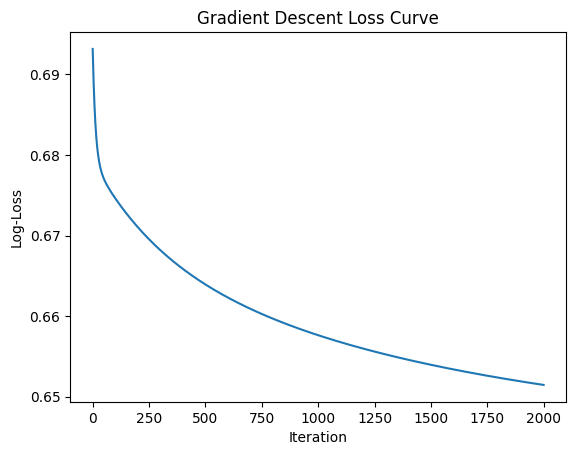

In [118]:
import matplotlib.pyplot as plt

plt.plot(loss_history)

plt.title("Gradient Descent Loss Curve")
plt.xlabel("Iteration")
plt.ylabel("Log-Loss")

plt.show()

In [119]:
print("NumPy weights:")
print(w)

print("\nScikit-learn weights:")
print(model_core.coef_[0])

print("\nDifference:")
print(w - model_core.coef_[0])

NumPy weights:
[1.26588942 0.89568718 0.26203096]

Scikit-learn weights:
[1.41815955 1.72704133 0.27194636]

Difference:
[-0.15227013 -0.83135415 -0.0099154 ]


In [120]:
from sklearn.linear_model import LogisticRegression

model_core_unregularized = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    max_iter=5000
)

model_core_unregularized.fit(X, y)

print("Unregularized scikit-learn weights:")
print(model_core_unregularized.coef_[0])


Unregularized scikit-learn weights:
[1.73283072 2.54778931 0.2987275 ]


In [121]:
print("NumPy weights:")
print(w)

print("\nUnregularized scikit-learn weights:")
print(model_core_unregularized.coef_[0])

print("\nDifference:")
print(w - model_core_unregularized.coef_[0])

NumPy weights:
[1.26588942 0.89568718 0.26203096]

Unregularized scikit-learn weights:
[1.73283072 2.54778931 0.2987275 ]

Difference:
[-0.4669413  -1.65210213 -0.03669654]


In [122]:
learning_rate = 0.5
iterations = 3000

w = np.zeros(X.shape[1])
b = 0
loss_history = []

for i in range(iterations):

    z = X @ w + b
    p = sigmoid(z)

    loss = -np.mean(
        y * np.log(p + 1e-15)
        + (1 - y) * np.log(1 - p + 1e-15)
    )

    loss_history.append(loss)

    gradient_w = X.T @ (p - y) / len(y)
    gradient_b = np.mean(p - y)

    w = w - learning_rate * gradient_w
    b = b - learning_rate * gradient_b

print("Final weights:", w)
print("Final bias:", b)
print("Initial loss:", loss_history[0])
print("Final loss:", loss_history[-1])

Final weights: [1.72056666 2.50881507 0.29754949]
Final bias: -2.7054667809188575
Initial loss: 0.6931471805599435
Final loss: 0.6446450155412864


In [123]:
print("Initial loss:", loss_history[0])
print("Final loss:", loss_history[-1])

print("\nLoss reduction:")
print(loss_history[0] - loss_history[-1])

Initial loss: 0.6931471805599435
Final loss: 0.6446450155412864

Loss reduction:
0.04850216501865712


In [124]:
print("NumPy weights:")
print(w)

print("\nUnregularized scikit-learn weights:")
print(model_core_unregularized.coef_[0])

print("\nDifference:")
print(w - model_core_unregularized.coef_[0])

NumPy weights:
[1.72056666 2.50881507 0.29754949]

Unregularized scikit-learn weights:
[1.73283072 2.54778931 0.2987275 ]

Difference:
[-0.01226406 -0.03897423 -0.00117801]


In [125]:
w_global = w.copy()

print("Global weights:")
print(w_global)

Global weights:
[1.72056666 2.50881507 0.29754949]


In [126]:
train_df = train_df.copy()

train_df["user_id"] = feedback.loc[
    train_df.index, "user_id"
].values

train_df["matched_user_id"] = feedback.loc[
    train_df.index, "matched_user_id"
].values

print(train_df[["user_id", "matched_user_id", "action"]].head())

  user_id matched_user_id  action
0    U001            U087       0
1    U001            U063       0
2    U001            U039       1
3    U001            U052       0
4    U001            U033       1


In [127]:
training_data = []

for _, row in feedback.iterrows():

    uid_a = row["user_id"]
    uid_b = row["matched_user_id"]

    training_data.append({
        "user_id": uid_a,
        "matched_user_id": uid_b,
        "text": TextSim_scaled[idx[uid_a], idx[uid_b]],
        "mbti": mbti_scaled_score(uid_a, uid_b),
        "location": location_score(uid_a, uid_b),
        "experience": experience_score(uid_a, uid_b),
        "interests": interest_score(uid_a, uid_b),
        "action": row["action"],
        "timestamp": row["timestamp"]
    })

training_df = pd.DataFrame(training_data)

training_df["timestamp"] = pd.to_datetime(training_df["timestamp"])

training_df = training_df.sort_values(
    "timestamp"
).reset_index(drop=True)

split_index = int(len(training_df) * 0.75)

train_df = training_df.iloc[:split_index].copy()
test_df = training_df.iloc[split_index:].copy()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nFirst training rows:")
print(train_df[["user_id", "matched_user_id", "action"]].head())

Training rows: 504
Testing rows: 169

First training rows:
  user_id matched_user_id  action
0    U066            U072       0
1    U087            U020       0
2    U014            U065       1
3    U005            U074       0
4    U015            U075       1


In [128]:
user_counts = train_df["user_id"].value_counts()

print("Minimum rows for one user:", user_counts.min())
print("Maximum rows for one user:", user_counts.max())
print("Average rows per user:", user_counts.mean())

Minimum rows for one user: 1
Maximum rows for one user: 10
Average rows per user: 5.6


In [129]:
def personalise_weights(user_id, w_global, lam, steps, lr):

    # Get this user's training rows
    user_data = train_df[train_df["user_id"] == user_id]

    # Get the user's features
    X_user = user_data[["text", "mbti", "location"]].values
    y_user = user_data["action"].values

    # Start from the global weights
    w_personal = w_global.copy()

    # Start with zero bias
    b_personal = 0.0

    # Learn from this user's rows
    for _ in range(steps):

        # Make predictions
        z = X_user @ w_personal + b_personal
        p = sigmoid(z)

        # Normal gradient
        gradient_w = X_user.T @ (p - y_user) / len(y_user)
        gradient_b = np.mean(p - y_user)

        # Pull weights back toward global weights
        gradient_w = gradient_w + lam * (w_personal - w_global)

        # Update weights
        w_personal = w_personal - lr * gradient_w
        b_personal = b_personal - lr * gradient_b

    return w_personal

In [130]:
personal_weights = personalise_weights(
    "U001",
    w_global,
    lam=1,
    steps=20,
    lr=0.1
)

print("Global weights:")
print(w_global)

print("\nPersonalized weights for U001:")
print(personal_weights)

Global weights:
[1.72056666 2.50881507 0.29754949]

Personalized weights for U001:
[1.53919424 2.09885787 0.13122426]


In [131]:
def personalise_weights(
    user_id,
    w_global,
    lam,
    steps,
    lr,
    data
):

    # Get this user's rows from the supplied data
    user_data = data[data["user_id"] == user_id]

    # If the user has no rows, return the global weights
    if len(user_data) == 0:
        return w_global.copy()

    # Get features and target
    X_user = user_data[["text", "mbti", "location"]].values
    y_user = user_data["action"].values

    # Start from global weights
    w_personal = w_global.copy()

    # Start bias at zero
    b_personal = 0.0

    for _ in range(steps):

        # Predictions
        z = X_user @ w_personal + b_personal
        p = sigmoid(z)

        # Normal gradients
        gradient_w = X_user.T @ (p - y_user) / len(y_user)
        gradient_b = np.mean(p - y_user)

        # Regularization: pull toward global weights
        gradient_w = gradient_w + lam * (
            w_personal - w_global
        )

        # Update
        w_personal = w_personal - lr * gradient_w
        b_personal = b_personal - lr * gradient_b

    return w_personal


In [132]:
personal_split = int(len(train_df) * 0.80)

personal_train_df = train_df.iloc[:personal_split].copy()
personal_val_df = train_df.iloc[personal_split:].copy()

print("Personalization training rows:", len(personal_train_df))
print("Personalization validation rows:", len(personal_val_df))

Personalization training rows: 403
Personalization validation rows: 101


In [133]:
lambdas = [0.1, 1, 10]

for lam in lambdas:

    validation_predictions = []

    for user_id in personal_val_df["user_id"].unique():

        personal_w = personalise_weights(
            user_id=user_id,
            w_global=w_global,
            lam=lam,
            steps=20,
            lr=0.1,
            data=personal_train_df
        )

        user_rows = personal_val_df[
            personal_val_df["user_id"] == user_id
        ]

        X_user = user_rows[
            ["text", "mbti", "location"]
        ].values

        scores = sigmoid(X_user @ personal_w)

        validation_predictions.extend(scores)

    print("Lambda:", lam)
    print("Number of predictions:", len(validation_predictions))
    print()

Lambda: 0.1
Number of predictions: 101

Lambda: 1
Number of predictions: 101

Lambda: 10
Number of predictions: 101



In [134]:
def personalise_weights(
    user_id,
    w_global,
    lam,
    steps,
    lr,
    data
):

    user_data = data[data["user_id"] == user_id]

    if len(user_data) == 0:
        return w_global.copy(), 0.0

    X_user = user_data[["text", "mbti", "location"]].values
    y_user = user_data["action"].values

    w_personal = w_global.copy()
    b_personal = 0.0

    for _ in range(steps):

        z = X_user @ w_personal + b_personal
        p = sigmoid(z)

        gradient_w = X_user.T @ (p - y_user) / len(y_user)
        gradient_b = np.mean(p - y_user)

        gradient_w = gradient_w + lam * (
            w_personal - w_global
        )

        w_personal = w_personal - lr * gradient_w
        b_personal = b_personal - lr * gradient_b

    return w_personal, b_personal

In [135]:
from sklearn.metrics import roc_auc_score

lambda_results = {}

for lam in [0.1, 1, 10]:

    validation_predictions = []
    validation_actual = []

    for user_id in personal_val_df["user_id"].unique():

        personal_w, personal_b = personalise_weights(
            user_id=user_id,
            w_global=w_global,
            lam=lam,
            steps=20,
            lr=0.1,
            data=personal_train_df
        )

        user_rows = personal_val_df[
            personal_val_df["user_id"] == user_id
        ]

        X_user = user_rows[
            ["text", "mbti", "location"]
        ].values

        predictions = sigmoid(
            X_user @ personal_w + personal_b
        )

        validation_predictions.extend(predictions)
        validation_actual.extend(user_rows["action"].values)

    auc = roc_auc_score(
        validation_actual,
        validation_predictions
    )

    lambda_results[lam] = auc

    print("Lambda:", lam)
    print("Validation ROC-AUC:", auc)
    print()

Lambda: 0.1
Validation ROC-AUC: 0.5726351351351351

Lambda: 1
Validation ROC-AUC: 0.5789695945945946

Lambda: 10
Validation ROC-AUC: 0.5819256756756757



In [136]:
best_lambda = max(
    lambda_results,
    key=lambda lam: lambda_results[lam]
)

print("Best lambda:", best_lambda)
print("Best validation ROC-AUC:", lambda_results[best_lambda])

Best lambda: 10
Best validation ROC-AUC: 0.5819256756756757


In [137]:
X_test = test_df[["text", "mbti", "location"]].values
y_test_personal = test_df["action"].values

global_test_scores = sigmoid(
    X_test @ w_global
)

print("Number of test predictions:", len(global_test_scores))
print("First 5 global scores:")
print(global_test_scores[:5])

Number of test predictions: 169
First 5 global scores:
[0.84960725 0.95136886 0.88066709 0.88446955 0.94713272]


In [138]:
personal_test_scores = []

for user_id in test_df["user_id"].unique():

    personal_w, personal_b = personalise_weights(
        user_id=user_id,
        w_global=w_global,
        lam=best_lambda,
        steps=20,
        lr=0.1,
        data=personal_train_df
    )

    user_rows = test_df[
        test_df["user_id"] == user_id
    ]

    X_user = user_rows[
        ["text", "mbti", "location"]
    ].values

    scores = sigmoid(
        X_user @ personal_w + personal_b
    )

    personal_test_scores.extend(scores)

print("Number of personalized test predictions:",
      len(personal_test_scores))

print("First 5 personalized scores:")
print(personal_test_scores[:5])

Number of personalized test predictions: 169
First 5 personalized scores:
[np.float64(0.7367651537688203), np.float64(0.8061014796470891), np.float64(0.9595760117128875), np.float64(0.9219186926674204), np.float64(0.9041634366980673)]


In [139]:
personal_test_scores = np.array(personal_test_scores)

global_auc = roc_auc_score(
    y_test_personal,
    global_test_scores
)

personal_auc = roc_auc_score(
    y_test_personal,
    personal_test_scores
)

print("Global model ROC-AUC:", global_auc)
print("Personalized model ROC-AUC:", personal_auc)

print("\nAUC improvement:",
      personal_auc - global_auc)

Global model ROC-AUC: 0.6968549796156087
Personalized model ROC-AUC: 0.4721898660454281

AUC improvement: -0.2246651135701806


In [140]:
users_with_personal_data = set(
    personal_train_df["user_id"]
)

users_in_test = set(
    test_df["user_id"]
)

users_without_history = users_in_test - users_with_personal_data

print("Users in test set:", len(users_in_test))
print("Users with personalization history:",
      len(users_in_test.intersection(users_with_personal_data)))

print("Users without personalization history:",
      len(users_without_history))

print("\nUsers without history:")
print(sorted(users_without_history))

Users in test set: 77
Users with personalization history: 76
Users without personalization history: 1

Users without history:
['U039']


In [141]:
import numpy as np

personal_test_scores = np.empty(len(test_df))

for user_id in test_df["user_id"].unique():

    personal_w, personal_b = personalise_weights(
        user_id=user_id,
        w_global=w_global,
        lam=best_lambda,
        steps=20,
        lr=0.1,
        data=personal_train_df
    )

    user_mask = test_df["user_id"] == user_id

    X_user = test_df.loc[
        user_mask,
        ["text", "mbti", "location"]
    ].values

    personal_test_scores[user_mask] = sigmoid(
        X_user @ personal_w + personal_b
    )

print("Number of personalized test predictions:", len(personal_test_scores))
print("Number of test rows:", len(test_df))

Number of personalized test predictions: 169
Number of test rows: 169


In [142]:
from sklearn.metrics import roc_auc_score

global_auc = roc_auc_score(
    y_test_personal,
    global_test_scores
)

personal_auc = roc_auc_score(
    y_test_personal,
    personal_test_scores
)

print("Global model ROC-AUC:", global_auc)
print("Personalized model ROC-AUC:", personal_auc)
print("AUC improvement:", personal_auc - global_auc)

Global model ROC-AUC: 0.6968549796156087
Personalized model ROC-AUC: 0.6638031450203844
AUC improvement: -0.033051834595224316


In [143]:
weight_distances = []

for user_id in test_df["user_id"].unique():

    personal_w, personal_b = personalise_weights(
        user_id=user_id,
        w_global=w_global,
        lam=best_lambda,
        steps=20,
        lr=0.1,
        data=personal_train_df
    )

    distance = np.linalg.norm(personal_w - w_global)
    weight_distances.append(distance)

print("Average weight distance:", np.mean(weight_distances))
print("Maximum weight distance:", np.max(weight_distances))
print("Minimum weight distance:", np.min(weight_distances))

Average weight distance: 0.031401446808712985
Maximum weight distance: 0.0936954681171053
Minimum weight distance: 0.0


In [144]:
np.random.seed(42)

n_interactions = 100

# Create 100 simulated pairs
simulation_features_professional = np.random.rand(n_interactions, 3)

professional_labels = []

for x in simulation_features_professional:

    text_score = x[0]

    # Strong professional-focused rule:
    # High TextSim -> accept
    # Low TextSim -> reject
    if text_score >= 0.5:
        label = 1
    else:
        label = 0

    # About 10% noise
    if np.random.rand() < 0.10:
        label = 1 - label

    professional_labels.append(label)

professional_labels = np.array(professional_labels)

print("Number of simulated interactions:", len(professional_labels))
print("Accepted:", professional_labels.sum())
print("Rejected:", len(professional_labels) - professional_labels.sum())
print("Approximate noise level: 10%")

Number of simulated interactions: 100
Accepted: 54
Rejected: 46
Approximate noise level: 10%


In [145]:
def online_update(w, b, x, y, learning_rate=0.1):
    """
    Perform one online gradient-descent update.

    w = current weights
    b = current bias
    x = one interaction's feature values
    y = actual label (0 or 1)
    """

    # Calculate prediction
    p = sigmoid(np.dot(x, w) + b)

    # Calculate error
    error = p - y

    # Calculate gradients for one interaction
    gradient_w = error * x
    gradient_b = error

    # Update weights and bias
    w = w - learning_rate * gradient_w
    b = b - learning_rate * gradient_b

    return w, b

In [146]:
print("w_global:", "defined" if "w_global" in globals() else "NOT defined")
print("simulation_features:", "defined" if "simulation_features" in globals() else "NOT defined")
print("professional_labels:", "defined" if "professional_labels" in globals() else "NOT defined")
print("n_interactions:", "defined" if "n_interactions" in globals() else "NOT defined")
print("online_update:", "defined" if "online_update" in globals() else "NOT defined")

w_global: defined
simulation_features: NOT defined
professional_labels: defined
n_interactions: defined
online_update: defined


In [147]:
simulation_features = []

for i in range(n_interactions):
    text_value = np.random.rand()
    mbti_value = np.random.rand()
    location_value = np.random.rand()

    simulation_features.append([
        text_value,
        mbti_value,
        location_value
    ])

simulation_features = np.array(simulation_features)

print("Simulation features created!")
print("Shape:", simulation_features.shape)
print("First row:", simulation_features[0])

Simulation features created!
Shape: (100, 3)
First row: [0.10312387 0.90255291 0.50525237]


In [148]:
import inspect

print(inspect.signature(online_update))

(w, b, x, y, learning_rate=0.1)


In [149]:
# Start from the global weights
w_professional = w_global.copy()
b_professional = 0.0

# Store the weights after every interaction
professional_history = []

for i in range(n_interactions):

    x = simulation_features[i]
    y = professional_labels[i]

    # One online learning step
    w_professional, b_professional = online_update(
        w_professional,
        b_professional,
        x,
        y,
        learning_rate=0.1
    )

    # Save the weights after this interaction
    professional_history.append(
        w_professional.copy()
    )

professional_history = np.array(
    professional_history
)

print("Starting global weights:")
print(w_global)

print("\nFinal professional-focused weights:")
print(w_professional)

print("\nHistory shape:")
print(professional_history.shape)

Starting global weights:
[1.72056666 2.50881507 0.29754949]

Final professional-focused weights:
[ 0.87578235  1.68682318 -0.17829115]

History shape:
(100, 3)


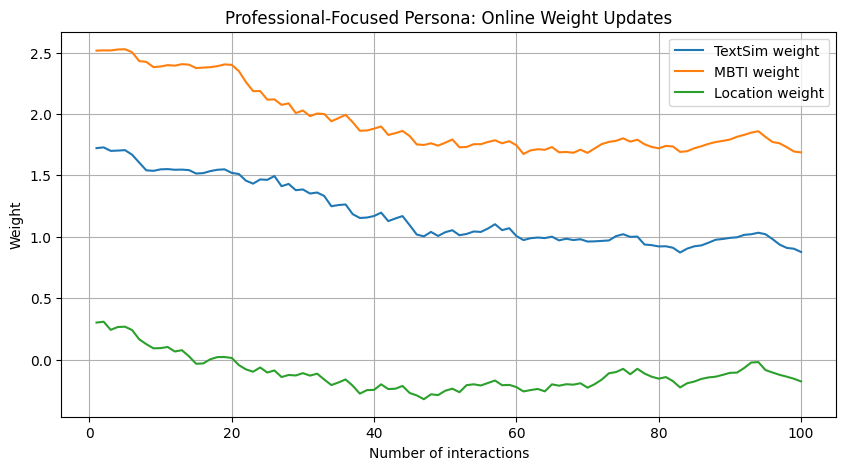

In [150]:
import matplotlib.pyplot as plt

interactions = np.arange(1, n_interactions + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    interactions,
    professional_history[:, 0],
    label="TextSim weight"
)

plt.plot(
    interactions,
    professional_history[:, 1],
    label="MBTI weight"
)

plt.plot(
    interactions,
    professional_history[:, 2],
    label="Location weight"
)

plt.xlabel("Number of interactions")
plt.ylabel("Weight")
plt.title("Professional-Focused Persona: Online Weight Updates")
plt.legend()
plt.grid(True)
plt.show()

In [151]:
np.random.seed(42)

n_interactions = 100

# Create 100 simulated pairs
simulation_features_professional = np.random.rand(n_interactions, 3)

professional_labels = []

for x in simulation_features_professional:

    text_score = x[0]

    # Strong professional-focused rule:
    # High TextSim -> accept
    # Low TextSim -> reject
    if text_score >= 0.5:
        label = 1
    else:
        label = 0

    # About 10% noise
    if np.random.rand() < 0.10:
        label = 1 - label

    professional_labels.append(label)

professional_labels = np.array(professional_labels)

print("Number of simulated interactions:", len(professional_labels))
print("Accepted:", professional_labels.sum())
print("Rejected:", len(professional_labels) - professional_labels.sum())
print("Approximate noise level: 10%")

Number of simulated interactions: 100
Accepted: 54
Rejected: 46
Approximate noise level: 10%


In [152]:
# Start from the real global weights
w_professional = w_global.copy()
b_professional = 0.0

# Store weights after every interaction
professional_history = []

for i in range(n_interactions):

    x = simulation_features_professional[i]
    y = professional_labels[i]

    # One gradient update
    w_professional, b_professional = online_update(
        w_professional,
        b_professional,
        x,
        y,
        learning_rate=0.1
    )

    # Save the weights
    professional_history.append(w_professional.copy())

professional_history = np.array(professional_history)

print("Starting global weights:")
print(w_global)

print("\nFinal professional-focused weights:")
print(w_professional)

print("\nHistory shape:", professional_history.shape)

Starting global weights:
[1.72056666 2.50881507 0.29754949]

Final professional-focused weights:
[ 1.78115685  1.61707422 -0.38077997]

History shape: (100, 3)


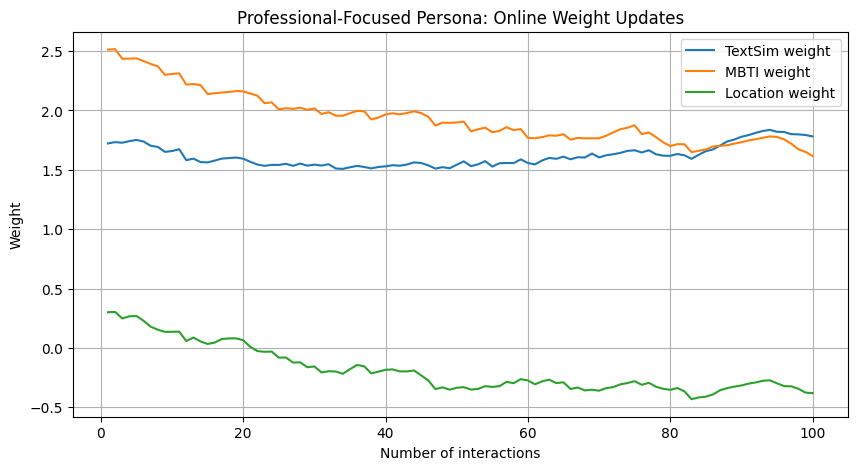

In [153]:
interactions = np.arange(1, n_interactions + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    interactions,
    professional_history[:, 0],
    label="TextSim weight"
)

plt.plot(
    interactions,
    professional_history[:, 1],
    label="MBTI weight"
)

plt.plot(
    interactions,
    professional_history[:, 2],
    label="Location weight"
)

plt.xlabel("Number of interactions")
plt.ylabel("Weight")
plt.title("Professional-Focused Persona: Online Weight Updates")
plt.legend()
plt.grid(True)
plt.show()

In [154]:
np.random.seed(123)

n_interactions_personality = 100

# Create 100 simulated pairs
simulation_features_personality = np.random.rand(
    n_interactions_personality,
    3
)

personality_labels = []

for x in simulation_features_personality:

    mbti_score = x[1]

    # Personality-focused rule:
    # High MBTI compatibility -> accept
    # Low MBTI compatibility -> reject
    if mbti_score >= 0.5:
        label = 1
    else:
        label = 0

    # About 10% random noise
    if np.random.rand() < 0.10:
        label = 1 - label

    personality_labels.append(label)

personality_labels = np.array(personality_labels)

print(
    "Number of simulated interactions:",
    len(personality_labels)
)

print(
    "Accepted:",
    personality_labels.sum()
)

print(
    "Rejected:",
    len(personality_labels) - personality_labels.sum()
)

print("Approximate noise level: 10%")

Number of simulated interactions: 100
Accepted: 49
Rejected: 51
Approximate noise level: 10%


In [155]:
# Start from the same global weights
w_personality = w_global.copy()
b_personality = 0.0

# Store weights after every interaction
personality_history = []

for i in range(n_interactions_personality):

    x = simulation_features_personality[i]
    y = personality_labels[i]

    # One online gradient update
    w_personality, b_personality = online_update(
        w_personality,
        b_personality,
        x,
        y,
        learning_rate=0.1
    )

    # Save weights after this interaction
    personality_history.append(w_personality.copy())

personality_history = np.array(personality_history)

print("Starting global weights:")
print(w_global)

print("\nFinal personality-focused weights:")
print(w_personality)

print("\nHistory shape:", personality_history.shape)

Starting global weights:
[1.72056666 2.50881507 0.29754949]

Final personality-focused weights:
[ 0.83939049  2.43757944 -0.42917805]

History shape: (100, 3)


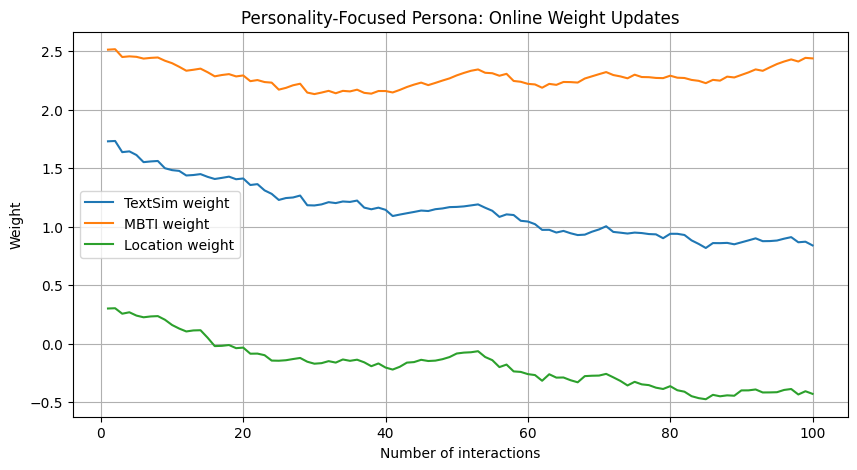

In [156]:
interactions_personality = np.arange(
    1,
    n_interactions_personality + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    interactions_personality,
    personality_history[:, 0],
    label="TextSim weight"
)

plt.plot(
    interactions_personality,
    personality_history[:, 1],
    label="MBTI weight"
)

plt.plot(
    interactions_personality,
    personality_history[:, 2],
    label="Location weight"
)

plt.xlabel("Number of interactions")
plt.ylabel("Weight")
plt.title("Personality-Focused Persona: Online Weight Updates")
plt.legend()
plt.grid(True)
plt.show()

In [157]:
np.random.seed(123)

n_interactions_personality = 200

# Create 200 simulated pairs
simulation_features_personality = np.random.rand(
    n_interactions_personality,
    3
)

personality_labels = []

for x in simulation_features_personality:

    mbti_score = x[1]

    # Personality-focused rule:
    # High MBTI compatibility -> accept
    # Low MBTI compatibility -> reject
    if mbti_score >= 0.5:
        label = 1
    else:
        label = 0

    # About 10% random noise
    if np.random.rand() < 0.10:
        label = 1 - label

    personality_labels.append(label)

personality_labels = np.array(personality_labels)

print("Number of simulated interactions:", len(personality_labels))
print("Accepted:", personality_labels.sum())
print("Rejected:", len(personality_labels) - personality_labels.sum())
print("Approximate noise level: 10%")

Number of simulated interactions: 200
Accepted: 99
Rejected: 101
Approximate noise level: 10%


In [158]:
# Start from the same global weights
w_personality = w_global.copy()
b_personality = 0.0

# Store weights after every interaction
personality_history = []

for i in range(n_interactions_personality):

    x = simulation_features_personality[i]
    y = personality_labels[i]

    # One online gradient update
    w_personality, b_personality = online_update(
        w_personality,
        b_personality,
        x,
        y,
        learning_rate=0.1
    )

    # Save the weights after this interaction
    personality_history.append(w_personality.copy())

personality_history = np.array(personality_history)

print("Starting global weights:")
print(w_global)

print("\nFinal personality-focused weights:")
print(w_personality)

print("\nHistory shape:", personality_history.shape)

Starting global weights:
[1.72056666 2.50881507 0.29754949]

Final personality-focused weights:
[ 0.42481914  3.03876938 -0.60688886]

History shape: (200, 3)


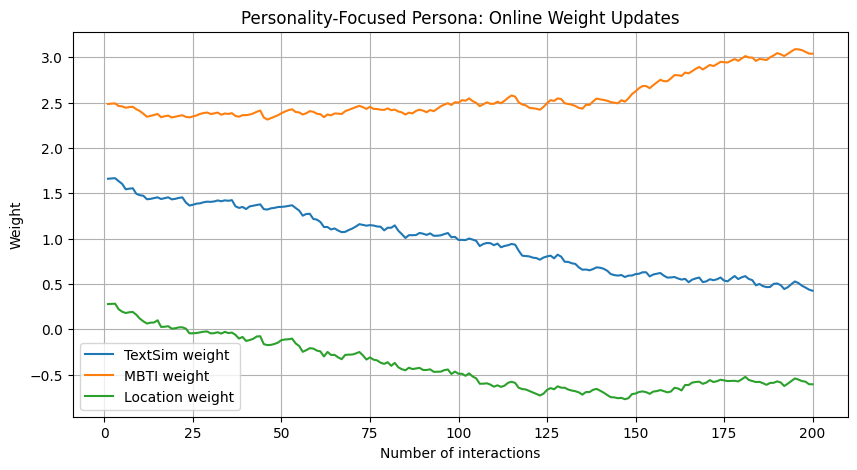

In [159]:
interactions_personality = np.arange(
    1,
    n_interactions_personality + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    interactions_personality,
    personality_history[:, 0],
    label="TextSim weight"
)

plt.plot(
    interactions_personality,
    personality_history[:, 1],
    label="MBTI weight"
)

plt.plot(
    interactions_personality,
    personality_history[:, 2],
    label="Location weight"
)

plt.xlabel("Number of interactions")
plt.ylabel("Weight")
plt.title("Personality-Focused Persona: Online Weight Updates")
plt.legend()
plt.grid(True)
plt.show()

In [160]:
import pandas as pd

method_comparison = pd.DataFrame({
    "Method": [
        "Random",
        "Equal weights",
        "Starting weights",
        "Learned 3 features",
        "Learned 5 features"
    ],
    "ROC-AUC": [
        0.46563774,
        0.79076878,
        0.71185207,
        0.70020384,
        0.80183460
    ],
    "Top-30% Accept Rate": [
        0.45098039,
        0.68627451,
        0.66666667,
        0.64705882,
        0.74509804
    ],
    "Lift": [
        1.12081892,
        1.70559400,
        1.65686275,
        1.60813149,
        1.85178777
    ]
})

method_comparison["Top-30% Accept Rate"] = (
    method_comparison["Top-30% Accept Rate"] * 100
)

method_comparison

,Method,ROC-AUC,Top-30% Accept Rate,Lift
0,Random,0.465638,45.098039,1.120819
1,Equal weights,0.790769,68.627451,1.705594
2,Starting weights,0.711852,66.666667,1.656863
3,Learned 3 features,0.700204,64.705882,1.608131
4,Learned 5 features,0.801835,74.509804,1.851788


In [161]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Features used by the learned 5-feature model
features = [
    "text",
    "mbti",
    "location",
    "experience",
    "interests"
]

# Fixed test set
X_test_learning = test_df[features].values
y_test_learning = test_df["action"].values

# Training percentages
percentages = np.arange(10, 101, 10)

# Number of random repetitions
n_repeats = 10

learning_curve_results = []

for percentage in percentages:

    subset_size = int(len(train_df) * percentage / 100)

    auc_scores = []

    for repeat in range(n_repeats):

        # Different random subset each repetition
        subset = train_df.sample(
            n=subset_size,
            random_state=repeat
        )

        X_train_subset = subset[features].values
        y_train_subset = subset["action"].values

        # Train logistic regression
        model = LogisticRegression(
            max_iter=5000
        )

        model.fit(
            X_train_subset,
            y_train_subset
        )

        # Predict probabilities on the SAME test set
        test_probabilities = model.predict_proba(
            X_test_learning
        )[:, 1]

        # Calculate AUC
        auc = roc_auc_score(
            y_test_learning,
            test_probabilities
        )

        auc_scores.append(auc)

    learning_curve_results.append({
        "Training %": percentage,
        "Training rows": subset_size,
        "Mean AUC": np.mean(auc_scores),
        "Std AUC": np.std(auc_scores)
    })

learning_curve_df = pd.DataFrame(
    learning_curve_results
)

learning_curve_df

,Training %,Training rows,Mean AUC,Std AUC
0,10,50,0.762798,2.513953e-02
1,20,100,0.780242,1.903692e-02
2,30,151,0.786372,1.417708e-02
3,40,201,0.795093,1.038813e-02
4,50,252,0.798675,7.578636e-03
5,60,302,0.802082,4.583621e-03
6,70,352,0.800670,4.167395e-03
7,80,403,0.801602,3.171468e-03
8,90,453,0.802766,3.348991e-03
9,100,504,0.801835,1.110223e-16


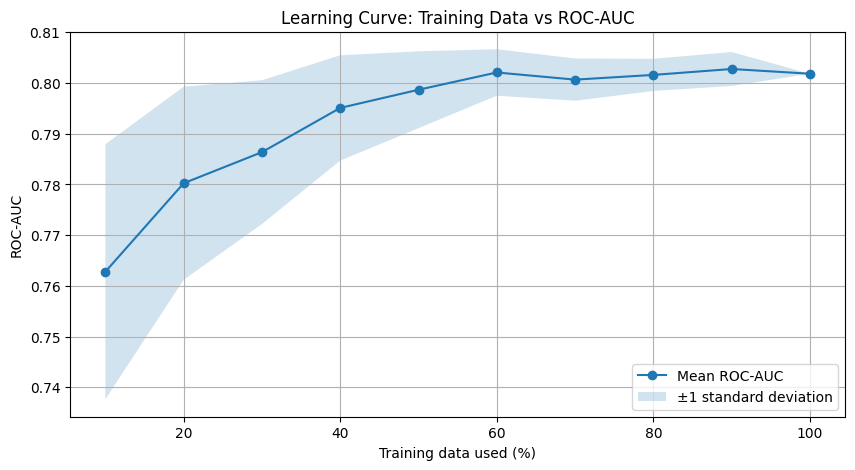

In [162]:
plt.figure(figsize=(10, 5))

x = learning_curve_df["Training %"]
mean_auc = learning_curve_df["Mean AUC"]
std_auc = learning_curve_df["Std AUC"]

plt.plot(
    x,
    mean_auc,
    marker="o",
    label="Mean ROC-AUC"
)

plt.fill_between(
    x,
    mean_auc - std_auc,
    mean_auc + std_auc,
    alpha=0.2,
    label="±1 standard deviation"
)

plt.xlabel("Training data used (%)")
plt.ylabel("ROC-AUC")
plt.title("Learning Curve: Training Data vs ROC-AUC")
plt.legend()
plt.grid(True)
plt.show()


In [163]:
# Make sure test data is in chronological order
online_test_df = test_df.sort_values("timestamp").reset_index(drop=True)

# Starting global weights
frozen_w = w_global.copy()
frozen_b = 0.0

online_w = w_global.copy()
online_b = 0.0

frozen_correct = []
online_correct = []

for _, row in online_test_df.iterrows():

    # Feature vector for this interaction
    x = row[
        ["text", "mbti", "location"]
    ].values.astype(float)

    y = row["action"]

    # -----------------------------
    # 1. FROZEN MODEL PREDICTION
    # -----------------------------
    frozen_probability = sigmoid(
        np.dot(x, frozen_w) + frozen_b
    )

    frozen_prediction = int(
        frozen_probability >= 0.5
    )

    frozen_correct.append(
        int(frozen_prediction == y)
    )

    # -----------------------------
    # 2. ONLINE MODEL PREDICTION
    # -----------------------------
    online_probability = sigmoid(
        np.dot(x, online_w) + online_b
    )

    online_prediction = int(
        online_probability >= 0.5
    )

    online_correct.append(
        int(online_prediction == y)
    )

    # -----------------------------
    # 3. UPDATE AFTER FEEDBACK
    # -----------------------------
    online_w, online_b = online_update(
        online_w,
        online_b,
        x,
        y,
        learning_rate=0.1
    )

# Convert to arrays
frozen_correct = np.array(frozen_correct)
online_correct = np.array(online_correct)

# Cumulative accuracy
frozen_cumulative_accuracy = np.cumsum(
    frozen_correct
) / np.arange(1, len(frozen_correct) + 1)

online_cumulative_accuracy = np.cumsum(
    online_correct
) / np.arange(1, len(online_correct) + 1)

print("Number of test interactions:", len(online_test_df))

print(
    "Final frozen accuracy:",
    frozen_cumulative_accuracy[-1]
)

print(
    "Final online accuracy:",
    online_cumulative_accuracy[-1]
)

Number of test interactions: 169
Final frozen accuracy: 0.40236686390532544
Final online accuracy: 0.5739644970414202


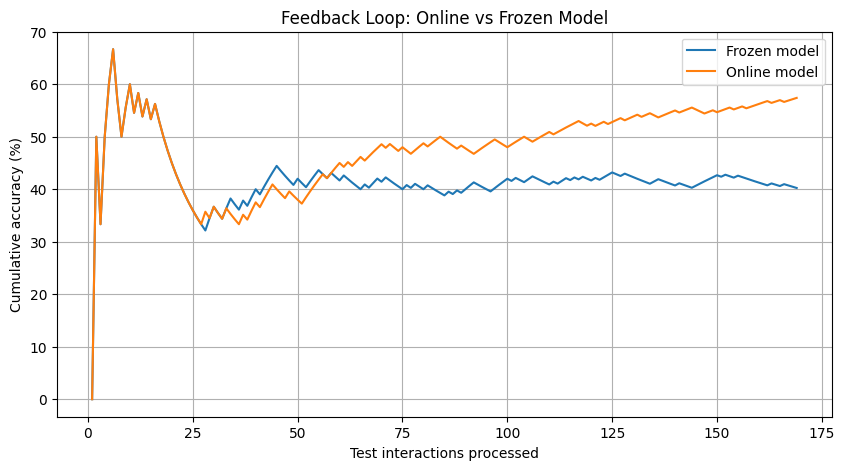

In [164]:
interactions = np.arange(
    1,
    len(online_test_df) + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    interactions,
    frozen_cumulative_accuracy * 100,
    label="Frozen model"
)

plt.plot(
    interactions,
    online_cumulative_accuracy * 100,
    label="Online model"
)

plt.xlabel("Test interactions processed")
plt.ylabel("Cumulative accuracy (%)")
plt.title("Feedback Loop: Online vs Frozen Model")
plt.legend()
plt.grid(True)
plt.show()

    Feature  Starting   Learned
0   TextSim  0.380074  0.415013
1      MBTI  0.554198  0.505404
2  Location  0.065729  0.079583


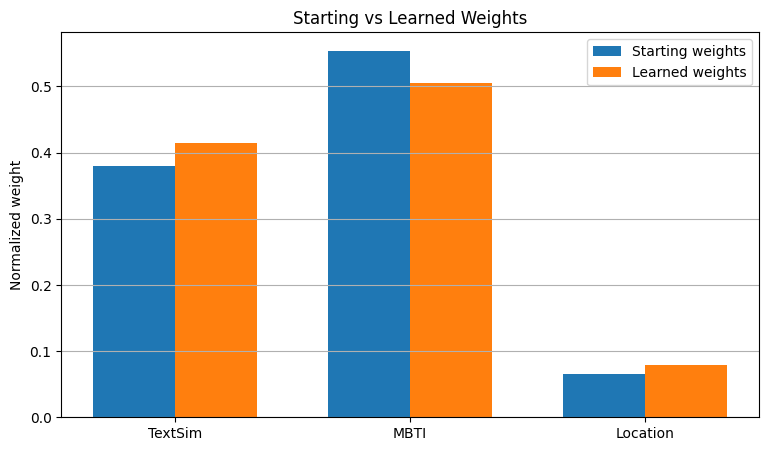

In [165]:
# Starting weights
starting_weights = np.array([
    w_global[0],
    w_global[1],
    w_global[2]
])

# Learned 3-feature weights from Part 9
learned_weights = np.array([
    0.41501271,
    0.50540442,
    0.07958286
])

# Normalize so each set sums to 1
starting_normalized = (
    starting_weights / starting_weights.sum()
)

learned_normalized = (
    learned_weights / learned_weights.sum()
)

weight_comparison = pd.DataFrame({
    "Feature": [
        "TextSim",
        "MBTI",
        "Location"
    ],
    "Starting": starting_normalized,
    "Learned": learned_normalized
})

print(weight_comparison)

# Plot
x = np.arange(3)
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    starting_normalized,
    width,
    label="Starting weights"
)

plt.bar(
    x + width / 2,
    learned_normalized,
    width,
    label="Learned weights"
)

plt.xticks(
    x,
    ["TextSim", "MBTI", "Location"]
)

plt.ylabel("Normalized weight")
plt.title("Starting vs Learned Weights")
plt.legend()
plt.grid(axis="y")

plt.show()

In [166]:
def mbti_score(mbti_a, mbti_b):
    score = 40

    if mbti_a[1] == mbti_b[1]:
        score += 10

    if mbti_a[2] != mbti_b[2]:
        score += 15

    if mbti_a[0] != mbti_b[0]:
        score += 15

    if mbti_a[3] == mbti_b[3]:
        score += 10

    golden_pairs = {
        frozenset(["INTJ", "ENFP"]),
        frozenset(["INTP", "ENTJ"]),
        frozenset(["INFJ", "ENTP"]),
        frozenset(["INFP", "ENFJ"]),
        frozenset(["ISTJ", "ESFP"]),
        frozenset(["ISFJ", "ESTP"]),
        frozenset(["ISTP", "ESFJ"]),
        frozenset(["ISFP", "ESTJ"])
    }

    if frozenset([mbti_a, mbti_b]) in golden_pairs:
        return 100

    return min(score, 100)


print("INTJ × ENFP:", mbti_score("INTJ", "ENFP"))
print("MBTI function restored successfully!")

INTJ × ENFP: 100
MBTI function restored successfully!


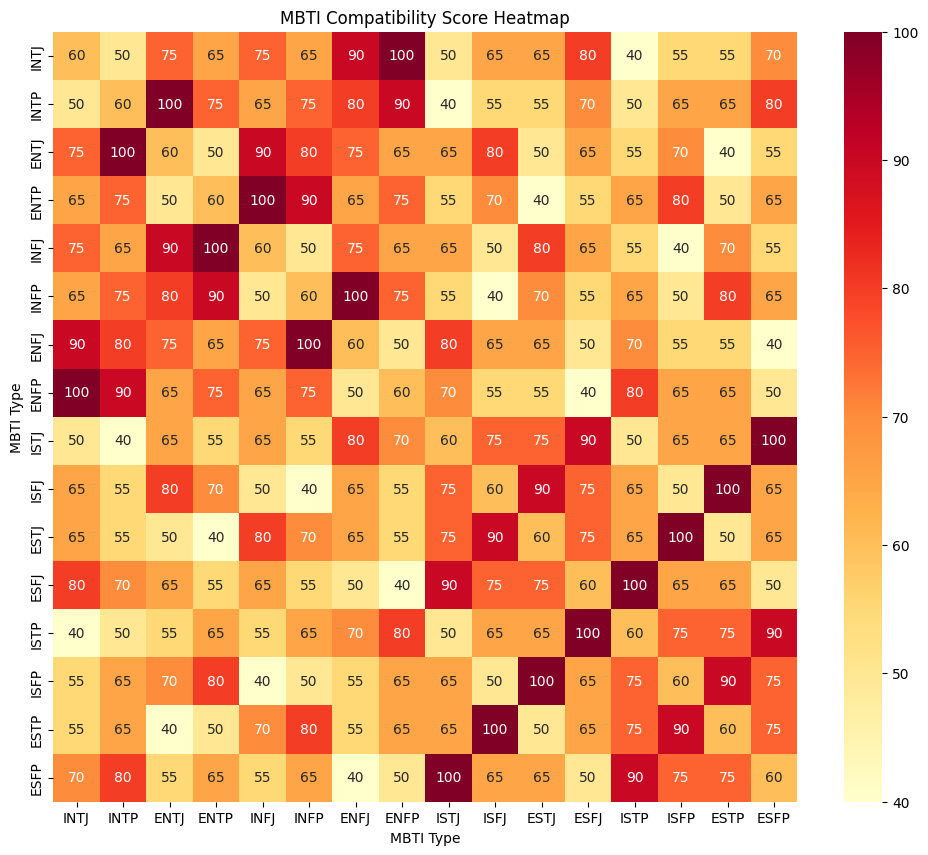

In [167]:
import seaborn as sns
import matplotlib.pyplot as plt

mbti_types = [
    "INTJ", "INTP", "ENTJ", "ENTP",
    "INFJ", "INFP", "ENFJ", "ENFP",
    "ISTJ", "ISFJ", "ESTJ", "ESFJ",
    "ISTP", "ISFP", "ESTP", "ESFP"
]

mbti_matrix = np.zeros(
    (len(mbti_types), len(mbti_types))
)

for i, mbti_a in enumerate(mbti_types):
    for j, mbti_b in enumerate(mbti_types):
        mbti_matrix[i, j] = mbti_score(
            mbti_a,
            mbti_b
        )

plt.figure(figsize=(12, 10))

sns.heatmap(
    mbti_matrix,
    xticklabels=mbti_types,
    yticklabels=mbti_types,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd"
)

plt.xlabel("MBTI Type")
plt.ylabel("MBTI Type")
plt.title("MBTI Compatibility Score Heatmap")

plt.show()

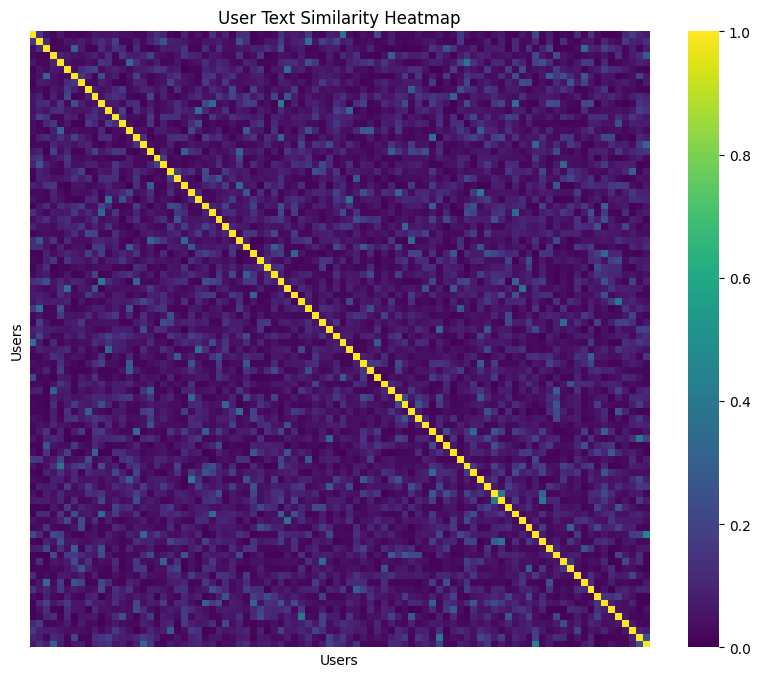

In [168]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    TextSim,
    cmap="viridis",
    xticklabels=False,
    yticklabels=False
)

plt.xlabel("Users")
plt.ylabel("Users")
plt.title("User Text Similarity Heatmap")

plt.show()

In [169]:
import os

print(os.listdir())

['.config', 'data', 'feedback.csv', 'summary_vectorizer.pkl', 'users_clean.csv', '__pycache__', 'users.csv', 'data_pipeline.py', 'about_vectorizer.pkl', 'sample_data']
